### Task 1: Data Preparation and Feature Engineering

In [1]:
# Install the required packages
%pip -q install yfinance lxml html5lib beautifulsoup4

In [2]:
# Load the libraries needed for this notebook
import json
import hashlib
import sys
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
import yfinance as yf
from IPython.display import display
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import sklearn

# Set up directories for raw data and generated results
project_dir = Path.cwd() / 'analysis'
# folder for the downloaded price files
raw_dir = project_dir / 'rawdata'
# folder for the results
results_dir = project_dir / 'results'

# create the folder if it does not exist
raw_dir.mkdir(parents=True, exist_ok=True)
# create the folder if it does not exist
results_dir.mkdir(parents=True, exist_ok=True)

# Define the date range under study
period_start = '2021-01-01'
# end date (exclusive): 1 Jan 2025
period_end = '2025-01-01'

# Fixed seed so that results can be reproduced
seed_value = 42

# Smallest cluster allowed (as a share of all shares) when K is chosen automatically
MIN_CLUSTER_FRAC = 0.03

# Optional manual choice of K per (feature set, method); leave empty to use the rule above.
# Example: selected_k_override = {('rfm', 'Ward'): 4, ('rfm', 'KMeans'): 4}
selected_k_override = {}

# Web page that lists the S&P 500 constituents
wiki_url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'

# Global plot styling
plt.rcParams.update({
    'figure.dpi': 110,
    'axes.grid': True,
    'axes.axisbelow': True,
    'grid.alpha': 0.2,
    'axes.spines.top': False,
    'axes.spines.right': False
})

# print the result
print("Libraries imported successfully.")
# print the result
print("Folders created successfully.")

Libraries imported successfully.
Folders created successfully.


### 1.1 Ticker selection and data acquisition

In [3]:
# Helper that writes a Python object to a JSON file
def write_json(target_path, payload):
    # write the object as readable JSON text
    target_path.write_text(
        json.dumps(payload, indent=2, default=str),
        encoding='utf-8'
    )


# Helper that returns the SHA256 digest of a file
# The digest reveals whether a file has been altered
def file_sha256(target_path):
    # compute and return the SHA256 hash of the file
    return hashlib.sha256(target_path.read_bytes()).hexdigest()


# Helper that collects the S&P 500 constituents and their price history
def fetch_market_data():

    # file where the constituent list is cached
    constituents_path = raw_dir / 'constituents.csv'

    # Reuse the saved constituent list when it exists
    if constituents_path.exists():
        # reuse the cached list (keeps the original retrieval date)
        constituents = pd.read_csv(constituents_path)

    else:
        # Scrape the constituent table from Wikipedia
        constituents = pd.read_html(
            wiki_url,
            storage_options={'User-Agent': 'Mozilla/5.0'}
        )[0]

        # Columns we need to keep
        needed_cols = [
            'Symbol',
            'Security',
            'GICS Sector',
            'GICS Sub-Industry'
        ]

        # stop if Wikipedia changed its table layout
        if not all(col in constituents.columns for col in needed_cols):
            # stop with a clear error message
            raise RuntimeError("The company data format has changed.")

        # keep only the needed columns
        constituents = constituents[needed_cols].copy()

        # Timestamp showing when the list was scraped
        constituents['retrieved_utc'] = datetime.now(timezone.utc).isoformat()

        # Save the constituent list for later runs
        constituents.to_csv(constituents_path, index=False)

    # Convert symbols to the Yahoo Finance convention
    constituents['YahooTicker'] = constituents['Symbol'].str.replace(
        '.', '-', regex=False
    )

    # Ticker of the market index used as benchmark
    index_symbol = '^GSPC'

    # Unique list of company tickers
    company_tickers = constituents['YahooTicker'].drop_duplicates().tolist()

    # Append the benchmark index to the download queue
    download_queue = company_tickers + [index_symbol]

    # Download each ticker one at a time
    failed_list = []

    # go through the tickers in batches of 25
    for batch_start in range(0, len(download_queue), 25):

        # tickers in this batch
        current_batch = download_queue[batch_start:batch_start + 25]

        # download one ticker at a time
        for symbol in current_batch:

            # Build the output file name for this ticker
            file_safe_symbol = symbol.replace('^', 'INDEX_')
            # CSV file that stores this ticker's prices
            price_path = raw_dir / f"{file_safe_symbol}.csv"

            # Do not download again if the file is already saved
            if price_path.exists():
                # skip to the next item
                continue

            # try the download; any error is caught below
            try:
                # Pull the daily price history
                price_history = yf.download(
                    symbol,
                    start=period_start,
                    end=period_end,
                    interval='1d',
                    auto_adjust=False,
                    actions=True,
                    progress=False,
                    threads=False,
                    multi_level_index=False
                )

                # Record the ticker if nothing came back
                if price_history is None or price_history.empty:
                    # remember this ticker as a failed download
                    failed_list.append(symbol)
                    # skip to the next item
                    continue

                # Flatten multi-level columns when present
                if isinstance(price_history.columns, pd.MultiIndex):
                    # use only the first level of the column names
                    price_history.columns = price_history.columns.get_level_values(0)

                # Standardise the date index
                price_history.index = pd.to_datetime(
                    price_history.index
                ).tz_localize(None).normalize()

                # name the index 'Date'
                price_history.index.name = 'Date'

                # Write the history to disk
                price_history.to_csv(price_path)

            except Exception as err:
                # remember this ticker as a failed download
                failed_list.append(symbol)
                # show which ticker failed and why
                print("Download failed:", symbol, str(err)[:150])

    # Confirm that the benchmark file was obtained
    index_path = raw_dir / 'INDEX_GSPC.csv'

    # the benchmark file is essential
    if not index_path.exists():
        # stop with a clear error message
        raise RuntimeError(
            "Benchmark data is unavailable. Please check the download."
        )

    # save the list of failed tickers
    pd.Series(failed_list, name='FailedTicker').to_csv(results_dir / 'failed_downloads.csv', index=False)
    # progress messages
    print("Stock data downloading completed.")
    # progress messages
    print("Failed downloads:", len(failed_list))

    # give the constituent table back to the caller
    return constituents


# Helper that loads the saved daily prices for one ticker
def load_price_file(symbol):

    # Rebuild the file name
    file_safe_symbol = symbol.replace('^', 'INDEX_')
    # CSV file that stores this ticker's prices
    price_path = raw_dir / f"{file_safe_symbol}.csv"

    # Nothing to load if the file is absent
    if not price_path.exists():
        # no file for this ticker
        return None

    # Read the saved CSV
    prices = pd.read_csv(
        price_path,
        index_col='Date',
        parse_dates=True
    )

    # Clean the dates and sort chronologically
    prices.index = pd.to_datetime(
        prices.index
    ).tz_localize(None).normalize()

    # return the prices in date order
    return prices.sort_index()

In [4]:
# Fetch the constituent list and all price histories
sp500_info = fetch_market_data()

# Show the first five rows of company information
display(sp500_info.head())

# Show how many company records were loaded
print("Total company records:", len(sp500_info))

# Show when the constituent list was retrieved
print("Data retrieved on:", sp500_info['retrieved_utc'].iloc[0])

# Collect the versions of the packages in use
package_versions = {
    'Python': sys.version.split()[0],
    'Pandas': pd.__version__,
    'NumPy': np.__version__,
    'SciPy': scipy.__version__,
    'Scikit-learn': sklearn.__version__,
    'Matplotlib': matplotlib.__version__,
    'yfinance': yf.__version__
}

# show the recorded package versions
display(pd.Series(package_versions, name='Version').to_frame())

# Record the data source, period and package versions on disk
write_json(results_dir / 'provenance.json', {
    'source': wiki_url,
    'price_source': 'Yahoo Finance via yfinance (auto_adjust=False; Close and Adj Close both kept)',
    'benchmark': '^GSPC',
    'data_retrieved_date': sp500_info['retrieved_utc'].iloc[0],
    'study_period': [period_start, period_end],
    'library_versions': package_versions,
    'file_hashes': {
        csv_file.name: file_sha256(csv_file)
        for csv_file in raw_dir.glob('*.csv')
    }
})

ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['Q']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['SNDK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:
1 Failed download:
ERRO

Stock data downloading completed.
Failed downloads: 5


,Symbol,Security,GICS Sector,GICS Sub-Industry,retrieved_utc,YahooTicker
0,MMM,3M,Industrials,Industrial Conglomerates,2026-11-24T02:29:48.977731+00:00,MMM
1,AOS,A. O. Smith,Industrials,Building Products,2026-11-24T02:29:48.977731+00:00,AOS
2,ABT,Abbott Laboratories,Health Care,Health Care Equipment,2026-11-24T02:29:48.977731+00:00,ABT
3,ABBV,AbbVie,Health Care,Biotechnology,2026-11-24T02:29:48.977731+00:00,ABBV
4,ACN,Accenture,Information Technology,IT Consulting & Other Services,2026-11-24T02:29:48.977731+00:00,ACN


Total company records: 503
Data retrieved on: 2026-11-24T02:29:48.977731+00:00


,Version
Python,3.13.18
Pandas,2.2.3
NumPy,2.4.6
SciPy,1.16.3
Scikit-learn,1.6.1
Matplotlib,3.10.0
yfinance,0.2.66


1.2 Data validation and alignment

In [5]:
# Load the S&P 500 index prices
index_prices = load_price_file('^GSPC')

# Restrict to the chosen date range
index_prices = index_prices.loc[
    (index_prices.index >= period_start) &
    (index_prices.index < period_end)
]

# Make sure no date is repeated
assert not index_prices.index.duplicated().any(), "Duplicate benchmark dates found"

# Verify the first and last trading days
assert index_prices.index.min() == pd.Timestamp('2021-01-04')
# last benchmark trading day must be 31 Dec 2024
assert index_prices.index.max() == pd.Timestamp('2024-12-31')

# Verify the adjusted close is finite and positive
assert np.isfinite(index_prices['Adj Close']).all()
# benchmark prices must be positive
assert index_prices['Adj Close'].gt(0).all()

# Last day of the sample
as_of_date = index_prices.index.max()

# Build the list of weekly Friday dates for the sample
# Short holiday weeks are still included
friday_calendar = pd.date_range(
    '2021-01-08',
    '2024-12-27',
    freq='W-FRI'
)

# Container for the price tables that pass every check
clean_prices = {}

# Container for the per-ticker check results
check_records = []

# Run the quality checks on every company
for firm in sp500_info.itertuples(index=False):

    # Yahoo ticker of this company
    symbol = firm.YahooTicker

    # Load the daily prices of this company
    daily_prices = load_price_file(symbol)

    # Collect reasons for exclusion here
    rejection_reasons = []

    # counters start as 'not computed'
    n_splits = np.nan
    # counters start as 'not computed'
    n_dividends = np.nan
    # counters start as 'not computed'
    n_missing = np.nan
    # counters start as 'not computed'
    n_split_lookback = np.nan
    # counters start as 'not computed'
    n_jumps = np.nan
    # counters start as 'not computed'
    n_adj_above = np.nan

    # columns every price file must contain
    mandatory_cols = [
        'Close',
        'Adj Close',
        'Volume',
        'Stock Splits',
        'Dividends'
    ]

    # Is any price file available?
    if daily_prices is None:
        # record why this company is excluded
        rejection_reasons.append('Unavailable data')

    else:

        # Cut the data to the study period
        daily_prices = daily_prices.loc[
            (daily_prices.index >= period_start) &
            (daily_prices.index < period_end)
        ]

        # Count benchmark trading days absent from this stock
        n_missing = len(
            index_prices.index.difference(daily_prices.index)
        )

        # Look for repeated dates
        if daily_prices.index.duplicated().any():
            # record why this company is excluded
            rejection_reasons.append('Duplicate dates')

        # Trading calendar must agree with the benchmark
        if n_missing or not daily_prices.index.isin(
            index_prices.index
        ).all():
            # record why this company is excluded
            rejection_reasons.append(
                'Incomplete or unequal trading history'
            )

        # All mandatory columns have to exist
        if not set(mandatory_cols).issubset(daily_prices.columns):
            # record why this company is excluded
            rejection_reasons.append('Missing required fields')

        else:

            # Look for missing or infinite entries
            if not np.isfinite(
                daily_prices[mandatory_cols].to_numpy()
            ).all():
                # record why this company is excluded
                rejection_reasons.append(
                    'Missing or nonfinite values'
                )

            # Prices must be strictly positive
            if daily_prices[['Close', 'Adj Close']].le(0).any().any():
                # record why this company is excluded
                rejection_reasons.append('Nonpositive prices')

            # Volume must be strictly positive
            if daily_prices['Volume'].le(0).any():
                # record why this company is excluded
                rejection_reasons.append('Nonpositive volume')

            # Tally the split and dividend days
            n_splits = int(
                daily_prices['Stock Splits'].ne(0).sum()
            )

            # number of dividend days
            n_dividends = int(
                daily_prices['Dividends'].ne(0).sum()
            )

            # Splits inside the 80 sessions used by the RFM baseline + window (logged, not excluded)
            n_split_lookback = int(daily_prices['Stock Splits'].tail(80).ne(0).sum())

            # Large one-day Close moves with no recorded split suggest unadjusted corporate actions (logged)
            n_jumps = int((
                daily_prices['Close'].pct_change().abs().gt(0.4)
                & daily_prices['Stock Splits'].eq(0)
            ).sum())

            # Adj Close should never exceed Close by more than rounding (logged)
            n_adj_above = int(
                (daily_prices['Adj Close'] > daily_prices['Close'] * 1.0001).sum()
            )

            # Corporate action values must not be negative
            if (
                daily_prices['Stock Splits'].lt(0).any()
                or daily_prices['Dividends'].lt(0).any()
            ):
                # record why this company is excluded
                rejection_reasons.append(
                    'Invalid corporate action values'
                )

    # Keep companies with no problems found
    if not rejection_reasons:
        # keep the company's prices
        clean_prices[symbol] = daily_prices

    # Log the outcome for this company
    check_records.append({
        'Ticker': symbol,
        'MissingSessions': n_missing,
        'SplitDays': n_splits,
        'DividendDays': n_dividends,
        'SplitsInRFMLookback': n_split_lookback,
        'UnexplainedJumps': n_jumps,
        'AdjCloseAboveClose': n_adj_above,
        'Status': 'Valid' if not rejection_reasons else 'Excluded',
        'Reason': '; '.join(rejection_reasons)
    })

# Turn the log into a table indexed by ticker
audit_table = pd.DataFrame(
    check_records
).set_index('Ticker')

# Report the last observation date
print("Final observation date:", as_of_date.date())

# At least one company must have passed
assert clean_prices, "No valid company stock data found"

# Show the audit table
display(audit_table)

# Report how many companies passed
print("Valid companies:", len(clean_prices))

# Exclusion summary by reason
display(audit_table.loc[audit_table["Status"] == "Excluded", "Reason"].value_counts().to_frame("Shares"))

Final observation date: 2024-12-31


,MissingSessions,SplitDays,DividendDays,SplitsInRFMLookback,UnexplainedJumps,AdjCloseAboveClose,Status,Reason
Ticker,,,,,,,,
MMM,0.0,1.0,16.0,0.0,0.0,0.0,Valid,
AOS,0.0,0.0,16.0,0.0,0.0,0.0,Valid,
ABT,0.0,0.0,16.0,0.0,0.0,0.0,Valid,
ABBV,0.0,0.0,16.0,0.0,0.0,0.0,Valid,
ACN,0.0,0.0,16.0,0.0,0.0,0.0,Valid,
...,...,...,...,...,...,...,...,...
XYL,0.0,0.0,16.0,0.0,0.0,0.0,Valid,
YUM,0.0,0.0,16.0,0.0,0.0,0.0,Valid,
ZBRA,0.0,0.0,0.0,0.0,0.0,0.0,Valid,


Valid companies: 486


,Shares
Reason,
Incomplete or unequal trading history,10
Unavailable data,5
Nonpositive volume,2


1.3 Weekly return and weekly beta

1.3.1 Mean weekly return

In [6]:
# Helper that turns daily prices into weekly returns
def compute_weekly_returns(daily_prices):

    # Take the final adjusted close of each week
    weekly_close = daily_prices['Adj Close'].resample('W-FRI').last()

    # Align to the Friday calendar
    weekly_close = weekly_close.reindex(friday_calendar)

    # Week-over-week percentage change
    weekly_change = weekly_close.pct_change(fill_method=None)

    # give back the weekly return series
    return weekly_change


# Weekly returns for the market index
index_returns = compute_weekly_returns(
    index_prices
).dropna()

# Weekly returns for every valid company
stock_returns = pd.DataFrame({
    symbol: compute_weekly_returns(prices)
    for symbol, prices in clean_prices.items()
})

# Align company returns to the benchmark dates
stock_returns = stock_returns.reindex(
    index_returns.index
)

# Confirm that no weekly return is missing
assert stock_returns.notna().all().all(), "Missing weekly returns found"

# Base table with company names and sectors
stock_table = sp500_info.set_index('YahooTicker').loc[
    list(clean_prices),
    ['Security', 'GICS Sector']
].copy()

# name the index 'Ticker'
stock_table.index.name = 'Ticker'

# Shorten the sector column name
stock_table.rename(
    columns={'GICS Sector': 'Sector'},
    inplace=True
)

# Average weekly return per company
stock_table['MeanWeeklyReturn'] = stock_returns.mean()

# Number of weekly observations per company
stock_table['WeeklyN'] = stock_returns.count()

# Report the aligned observations and check the week labels
print("Aligned weekly return observations:", len(index_returns))
# show the first and last week with a return
print("First / last return week:", index_returns.index.min().date(), index_returns.index.max().date())
# share and benchmark must use identical week labels
assert (stock_returns.index == index_returns.index).all()

# Holiday-shortened weeks are retained (fewer than 5 sessions)
sessions_per_week = index_prices['Adj Close'].resample('W-FRI').count().reindex(index_returns.index)
# count the holiday weeks kept
print("Holiday-shortened weeks retained:", int((sessions_per_week < 5).sum()))

# Independent check of one share with explicit Friday-to-Friday arithmetic
chk = next(iter(clean_prices))
# weekly closes for the check share
weekly_px = clean_prices[chk]['Adj Close'].resample('W-FRI').last()
# weekly returns computed by hand
manual = weekly_px.loc[index_returns.index] / weekly_px.shift(1).loc[index_returns.index] - 1
# hand calculation must match the main calculation
assert np.allclose(manual.values, stock_returns[chk].values)

# Show the outcome
display(
    stock_table[['MeanWeeklyReturn', 'WeeklyN']]
)

Aligned weekly return observations: 207
First / last return week: 2021-01-15 2024-12-27
Holiday-shortened weeks retained: 37


,MeanWeeklyReturn,WeeklyN
Ticker,,
MMM,0.001142,207
AOS,0.001991,207
ABT,0.000971,207
ABBV,0.003749,207
ACN,0.002376,207
...,...,...
XYL,0.001358,207
YUM,0.001807,207
ZBRA,0.001181,207


1.3.2 Weekly beta

In [7]:
# Variance of the market's weekly returns
index_var = index_returns.var()

# Market variance has to be positive
assert index_var > 0

# Beta of every company against the market
stock_table['WeeklyBeta'] = stock_returns.apply(
    lambda one_stock:
    one_stock.cov(index_returns) / index_var
)

# Show the betas
display(
    stock_table[['WeeklyBeta', 'WeeklyN']]
)

# Independent check: beta equals the OLS slope of share returns on benchmark returns
assert np.isclose(
    np.polyfit(index_returns.values, stock_returns[chk].values, 1)[0],
    stock_table.loc[chk, 'WeeklyBeta']
)
# number of weeks behind each beta
print("Aligned weekly observations used for beta:", len(index_returns))


,WeeklyBeta,WeeklyN
Ticker,,
MMM,0.869079,207
AOS,1.042805,207
ABT,0.583543,207
ABBV,0.425366,207
ACN,1.143300,207
...,...,...
XYL,1.138380,207
YUM,0.631435,207
ZBRA,1.618418,207


Aligned weekly observations used for beta: 207


1.4 Adapted RFM Calculations

1.4.1 Recency

In [8]:
# Dictionary that holds volume-spike information per company
volume_events = {}

# Examine volume spikes for each company
for symbol, daily_prices in clean_prices.items():

    # Mean volume over the prior 20 sessions
    prior_mean_volume = (
        daily_prices['Volume']
        .shift(1)
        .rolling(20, min_periods=20)
        .mean()
    )

    # A spike is a day with volume above double the prior mean
    spike_flag = (
        daily_prices['Volume'].gt(2 * prior_mean_volume)
        & prior_mean_volume.notna()
    )

    # The last 60 days must have a full look-back window
    assert prior_mean_volume.tail(60).notna().all()

    # Keep the spike details
    volume_events[symbol] = pd.DataFrame({
        'Close': daily_prices['Close'],
        'Volume': daily_prices['Volume'],
        'PreviousAverageVolume': prior_mean_volume,
        'VolumeThreshold': 2 * prior_mean_volume,
        'Qualifies': spike_flag
    })


# Boundary checks: every share ends on the observation date
assert all(t.index[-1] == as_of_date for t in volume_events.values())

# Independent loop check of the rolling rule (the tested day is excluded from its own baseline)
for symbol in list(volume_events)[:5]:
    # daily volume of this share
    vol = clean_prices[symbol]['Volume']
    # test each of the last 60 sessions
    for pos in range(len(vol) - 60, len(vol)):
        # mean volume of the previous 20 sessions (today excluded)
        base = vol.iloc[pos - 20:pos].mean()
        # spike flag must match the main calculation
        assert (vol.iloc[pos] > 2 * base) == bool(volume_events[symbol]['Qualifies'].iloc[pos])

# Date of the most recent spike for every company
last_spike_dates = pd.Series({
    symbol: spike_table.index[spike_table['Qualifies']].max()
    for symbol, spike_table in volume_events.items()
})

# Add the observation date
stock_table['ObservationDate'] = as_of_date

# Add the last spike date
stock_table['LatestEvent'] = last_spike_dates

# Recency measured in calendar days
stock_table['R'] = (
    as_of_date - last_spike_dates
).dt.days

# Companies that never had a spike
no_spike_tickers = stock_table.index[
    stock_table['R'].isna()
]

# Reflect this in the audit table
audit_table.loc[
    no_spike_tickers, 'Status'
] = 'Excluded'

# update the exclusion log
audit_table.loc[
    no_spike_tickers, 'Reason'
] = 'No qualifying high-volume event; Recency missing'

# check the same-day event case
print("Shares with an event on the observation date (R = 0):", int((stock_table['R'] == 0).sum()))
# shares excluded because no event exists
print("Shares with no qualifying event (excluded from RFM):", len(no_spike_tickers))

# Show recency
display(
    stock_table[['ObservationDate', 'LatestEvent', 'R']]
)

Shares with an event on the observation date (R = 0): 0
Shares with no qualifying event (excluded from RFM): 0


,ObservationDate,LatestEvent,R
Ticker,,,
MMM,2024-12-31,2024-12-20,11
AOS,2024-12-31,2024-12-20,11
ABT,2024-12-31,2024-12-20,11
ABBV,2024-12-31,2024-12-20,11
ACN,2024-12-31,2024-12-20,11
...,...,...,...
XYL,2024-12-31,2024-11-25,36
YUM,2024-12-31,2024-11-05,56
ZBRA,2024-12-31,2024-12-20,11


1.4.2 Frequency

In [9]:
# Number of spike days within the last 60 sessions
stock_table['F'] = pd.Series({
    symbol: int(spike_table['Qualifies'].tail(60).sum())
    for symbol, spike_table in volume_events.items()
})

# Show frequency
display(stock_table[['F']])

,F
Ticker,
MMM,4
AOS,2
ABT,1
ABBV,3
ACN,2
...,...
XYL,3
YUM,1
ZBRA,4


1.4.3 Monetary

In [10]:
# Dollar trading value over the last 60 sessions
stock_table['M'] = pd.Series({
    symbol: (
        spike_table['Close'] * spike_table['Volume']
    ).tail(60).sum()
    for symbol, spike_table in volume_events.items()
})

# Show monetary value
display(stock_table[['M']])

,M
Ticker,
MMM,2.599146e+10
AOS,4.748980e+09
ABT,3.523027e+10
ABBV,6.837054e+10
ACN,5.199430e+10
...,...
XYL,1.017679e+10
YUM,1.339492e+10
ZBRA,8.326927e+09


1.5 Metric interpretation and supporting evidence

In [11]:
# Final share set = valid shares that also have a defined Recency
final_table = stock_table.dropna(subset=['R']).reset_index()   # 'Ticker' becomes a column
# Recency as whole days
final_table['R'] = final_table['R'].astype(int)

# Update the inclusion / exclusion log
audit_table.loc[pd.Index(final_table['Ticker']), 'Status'] = 'Included'
# save the inclusion / exclusion log
audit_table.to_csv(results_dir / 'inclusion_exclusion_log.csv')

# how many shares are included / excluded
display(audit_table['Status'].value_counts().to_frame('Shares'))
# list of excluded shares and reasons
display(audit_table[audit_table['Status'] != 'Included'])

# Enough companies must remain for 2 to 8 clusters
assert len(final_table) >= 9, "Not enough companies for cluster counts 2 to 8"

# Columns used in the analysis
core_metrics = ['MeanWeeklyReturn', 'WeeklyBeta', 'R', 'F', 'M']

# Summary statistics (with skewness) of the core metrics
display(final_table[core_metrics].describe())
# skewness of each metric
display(final_table[core_metrics].skew().to_frame('Skewness').round(3))

# Worked example: first included share
sample_firm = final_table.iloc[0]
# daily table of the example share
sample_events = volume_events[sample_firm.Ticker]
# its latest 60 sessions
sample_recent60 = sample_events.tail(60).copy()
# daily traded value = Close x Volume
sample_recent60['TradingValue'] = sample_recent60['Close'] * sample_recent60['Volume']

# worked example summary
display(sample_firm[['Ticker', 'ObservationDate', 'LatestEvent', 'R', 'F', 'M']].to_frame('Worked Example'))
# row of the latest qualifying event
display(sample_events.loc[[sample_firm.LatestEvent]])
# the 60 sessions used for F and M
display(sample_recent60)

# Cross-check the RFM numbers
assert sample_recent60['Qualifies'].sum() == sample_firm.F
# M must equal the 60-day sum
assert np.isclose(sample_recent60['TradingValue'].sum(), sample_firm.M)
# R must equal the calendar-day difference
assert (as_of_date - sample_firm.LatestEvent).days == sample_firm.R

# Cross-check the 20-session prior average volume on the event date
assert np.isclose(
    sample_events.loc[sample_firm.LatestEvent, 'PreviousAverageVolume'],
    sample_events.loc[:sample_firm.LatestEvent, 'Volume'].iloc[-21:-1].mean()
)

# Add the observation date to the provenance record
provenance_record = json.loads((results_dir / 'provenance.json').read_text())
# store the observation date
provenance_record['observation_date'] = str(as_of_date.date())
# save the updated provenance file
write_json(results_dir / 'provenance.json', provenance_record)

# completion messages
print("Task 1 completed successfully.")
# completion messages
print("Final number of companies:", len(final_table))


,Shares
Status,
Included,486
Excluded,17


,MissingSessions,SplitDays,DividendDays,SplitsInRFMLookback,UnexplainedJumps,AdjCloseAboveClose,Status,Reason
Ticker,,,,,,,,
APP,70.0,0.0,0.0,0.0,1.0,0.0,Excluded,Incomplete or unequal trading history
COIN,69.0,0.0,0.0,0.0,0.0,0.0,Excluded,Incomplete or unequal trading history
CEG,263.0,0.0,12.0,0.0,0.0,0.0,Excluded,Incomplete or unequal trading history
EXE,26.0,0.0,15.0,0.0,0.0,0.0,Excluded,Incomplete or unequal trading history
FDXF,NaN,NaN,NaN,NaN,NaN,NaN,Excluded,Unavailable data
FERG,0.0,0.0,13.0,0.0,0.0,0.0,Excluded,Nonpositive volume
GEHC,492.0,0.0,7.0,0.0,0.0,0.0,Excluded,Incomplete or unequal trading history
GEV,812.0,0.0,1.0,0.0,0.0,0.0,Excluded,Incomplete or unequal trading history
HONA,NaN,NaN,NaN,NaN,NaN,NaN,Excluded,Unavailable data


,MeanWeeklyReturn,WeeklyBeta,R,F,M
count,486.000000,486.000000,486.000000,486.000000,4.860000e+02
mean,0.002857,0.973695,20.407407,2.989712,3.940419e+10
std,0.002652,0.407339,21.342438,1.330800,1.291388e+11
min,-0.004468,0.055453,4.000000,0.000000,1.297483e+09
25%,0.001182,0.666599,11.000000,2.000000,1.019517e+10
50%,0.002619,0.950610,11.000000,3.000000,1.668382e+10
75%,0.004207,1.179538,14.750000,4.000000,3.227689e+10
max,0.017772,3.778560,222.000000,8.000000,1.847697e+12


,Skewness
MeanWeeklyReturn,0.868
WeeklyBeta,1.104
R,3.646
F,0.425
M,11.684


,Worked Example
Ticker,MMM
ObservationDate,2024-12-31 00:00:00
LatestEvent,2024-12-20 00:00:00
R,11
F,4
M,25991458733.34198


,Close,Volume,PreviousAverageVolume,VolumeThreshold,Qualifies
Date,,,,,
2024-12-20,129.279999,8351300,3027540.0,6055080.0,True


,Close,Volume,PreviousAverageVolume,VolumeThreshold,Qualifies,TradingValue
Date,,,,,,
2024-10-07,134.850006,2254200,3568210.0,7136420.0,False,3.039789e+08
2024-10-08,134.690002,2882100,3500105.0,7000210.0,False,3.881901e+08
2024-10-09,135.009995,2671400,3507585.0,7015170.0,False,3.606657e+08
2024-10-10,133.460007,3060100,3476965.0,6953930.0,False,4.084010e+08
2024-10-11,134.750000,3103600,3431030.0,6862060.0,False,4.182101e+08
2024-10-14,135.759995,2207900,3452705.0,6905410.0,False,2.997445e+08
2024-10-15,135.729996,2465800,3409635.0,6819270.0,False,3.346830e+08
2024-10-16,136.350006,2021100,3334475.0,6668950.0,False,2.755770e+08
2024-10-17,135.679993,2328500,3287485.0,6574970.0,False,3.159309e+08


Task 1 completed successfully.
Final number of companies: 486




## Task 2 – Stock segmentation and sensitivity analysis


2.1 Feature preparation

,Skewness,IQR Outliers
MeanWeeklyReturn,0.8675,15
WeeklyBeta,1.1036,10
R,3.6458,115
F,0.4247,2
M,11.6838,45
LogM,1.0791,13


,raw_skew,log1p_skew
R,3.646,1.583
F,0.425,-0.928


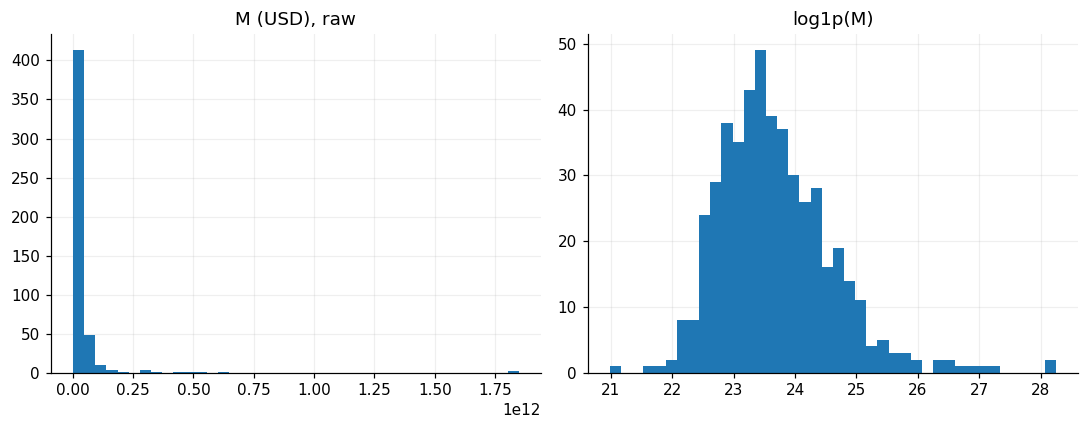

In [12]:
# Work on a copy of the Part 1 table
features = final_table.copy()

# Core variables of the analysis
metrics = [
    'MeanWeeklyReturn',
    'WeeklyBeta',
    'R',
    'F',
    'M'
]

# Log-transform the monetary value to reduce skew
features['LogM'] = np.log1p(features['M'])

# All columns checked for outliers
feature_columns = metrics + ['LogM']

# Lower and upper quartiles
q1_values = features[feature_columns].quantile(0.25)
# upper quartile
q3_values = features[feature_columns].quantile(0.75)

# Interquartile range
iqr_values = q3_values - q1_values

# Outliers according to the 1.5 x IQR rule
is_outlier = (
    (features[feature_columns] <
     q1_values - 1.5 * iqr_values)
    |
    (features[feature_columns] >
     q3_values + 1.5 * iqr_values)
)

# Skewness and outlier counts side by side
skew_and_outliers = pd.DataFrame({
    'Skewness': features[feature_columns].skew(),
    'IQR Outliers': is_outlier.sum()
})

# show the skewness and outlier table
display(skew_and_outliers.round(4))

# Diagnostic only: would log1p also help the other skewed inputs? (R and F are left untransformed)
skew_check = pd.DataFrame({
    'raw_skew': features[['R', 'F']].skew(),
    'log1p_skew': np.log1p(features[['R', 'F']]).skew()
})
# show skewness before and after log1p
display(skew_check.round(3))

# Effect of log1p on Monetary
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
# histogram of raw M
axes[0].hist(features['M'], bins=40)
# title
axes[0].set_title('M (USD), raw')
# histogram of log1p(M)
axes[1].hist(features['LogM'], bins=40)
# title
axes[1].set_title('log1p(M)')
# tidy the layout
fig.tight_layout()
# draw the figure
plt.show()


In [13]:
# Dictionary to hold the standardised matrices
scaled_matrices = {}

# Feature sets for the two analyses
feature_groups = {
    'risk': ['MeanWeeklyReturn', 'WeeklyBeta'],
    'rfm': ['R', 'F', 'LogM']
}

# Let pandas print every row
pd.set_option('display.max_rows', None)

# Standardise each feature set independently
for set_name, set_columns in feature_groups.items():

    # Initialise the scaler
    z_scaler = StandardScaler()

    # Fit and transform
    z_values = z_scaler.fit_transform(
        features[set_columns]
    )

    # Store as a DataFrame
    scaled_matrices[set_name] = pd.DataFrame(
        z_values,
        columns=set_columns,
        index=features['Ticker']
    )

    # message
    print("Standardised", set_name.upper(), "features")
    # show the standardised matrix
    display(scaled_matrices[set_name])

# Restore the default row display limit
pd.reset_option('display.max_rows')

Standardised RISK features


,MeanWeeklyReturn,WeeklyBeta
Ticker,,
MMM,-0.647333,-0.257093
AOS,-0.327124,0.169836
ABT,-0.711938,-0.958794
ABBV,0.336742,-1.347513
ACN,-0.181507,0.416802
ADBE,-0.704886,1.424923
AMD,0.289522,2.221388
AES,-1.614635,0.418307
AFL,0.810553,-0.654920


Standardised RFM features


,R,F,LogM
Ticker,,,
MMM,-0.441238,0.759941,0.317572
AOS,-0.441238,-0.744463,-1.488397
ABT,-0.441238,-1.496666,0.640699
ABBV,-0.441238,0.007739,1.345132
ACN,-0.441238,-0.744463,1.054229
ADBE,-0.112915,0.007739,1.780920
AMD,-0.112915,0.759941,2.961937
AES,1.575603,0.007739,-0.577245
AFL,-0.441238,-0.744463,-0.395499


In [14]:
# Helper that returns the standardised array and its column names
def get_model_data(set_name):

    # standardised matrix of the chosen feature set
    chosen_matrix = scaled_matrices[set_name]

    # Return values and column names
    return (
        chosen_matrix.to_numpy(),
        list(chosen_matrix.columns)
    )


# Helper that shows a figure and then closes it
def display_chart(fig):

    # tidy the layout
    fig.tight_layout()
    # draw the figure
    plt.show()
    # free the memory
    plt.close(fig)


# message
print("Helper functions created successfully.")

Helper functions created successfully.


2.2 Agglomerative clustering (Ward method)

In [15]:
# Runs Ward or K-means clustering for both feature sets
def perform_clustering(frame, method_label):

    # lists that collect results
    score_rows, profile_rows, size_rows, candidate_profile_rows = [], [], [], []
    # cluster labels by name
    label_store = {}

    # Smallest acceptable cluster (at least 2 shares and MIN_CLUSTER_FRAC of all shares)
    min_allowed = max(2, int(np.ceil(MIN_CLUSTER_FRAC * len(frame))))

    # mean and median of every metric for one cluster (original units)
    def profile_stats(members):
        # result dictionary
        out = {}
        # loop over the five metrics
        for metric_name in metrics:
            # mean
            out[metric_name] = members[metric_name].mean()
            # median (robust to outliers)
            out['Median_' + metric_name] = members[metric_name].median()
        # give back the profile
        return out

    # repeat for the risk/return matrix and the RFM matrix
    for set_name in ['risk', 'rfm']:

        # standardised data of this feature set
        model_input, input_columns = get_model_data(set_name)
        # evaluation rows for K = 2 ... 8
        k_results = []
        # largest K tried (8)
        k_limit = min(8, len(frame) - 1)

        # try every K from 2 to 8
        for k_value in range(2, k_limit + 1):

            # choose the algorithm
            if method_label == 'Ward':
                # Ward linkage (Euclidean distance)
                cluster_model = AgglomerativeClustering(n_clusters=k_value, linkage='ward')
                # cluster number for every share
                assigned_labels = cluster_model.fit_predict(model_input)
                # Ward has no inertia
                sse_value = np.nan
            else:
                # K-means with 30 random starts and a fixed seed
                cluster_model = KMeans(n_clusters=k_value, random_state=seed_value, n_init=30)
                # cluster number for every share
                assigned_labels = cluster_model.fit_predict(model_input)
                # K-means inertia = within-cluster sum of squares
                sse_value = float(cluster_model.inertia_)

            # number of shares in each cluster
            members_per_cluster = pd.Series(assigned_labels).value_counts().sort_index()

            # silhouette needs at least 2 clusters
            if 1 < len(members_per_cluster) < len(frame):
                # silhouette: higher = better separated clusters
                sil_score = silhouette_score(model_input, assigned_labels)
            else:
                # silhouette not defined
                sil_score = np.nan

            # Skip solutions with fewer clusters than requested
            if len(members_per_cluster) != k_value or not np.isfinite(sil_score):
                # skip to the next item
                continue

            # profile every cluster of this K
            for cluster_id in members_per_cluster.index:
                # the shares in this cluster
                members = frame.loc[assigned_labels == cluster_id]
                # store the profile of this candidate cluster
                candidate_profile_rows.append({
                    'FeatureSet': set_name, 'Method': method_label, 'K': k_value,
                    'Cluster': int(cluster_id), 'Size': len(members),
                    **profile_stats(members)
                })

            # store the quality scores of this K
            k_results.append({
                'FeatureSet': set_name, 'Method': method_label, 'K': k_value,
                'Silhouette': float(sil_score), 'Inertia': sse_value,
                'MinClusterSize': int(members_per_cluster.min()),
                'MaxClusterSize': int(members_per_cluster.max())
            })

            # store the cluster sizes
            for cluster_id, member_count in members_per_cluster.items():
                # store one size row
                size_rows.append({
                    'FeatureSet': set_name, 'Method': method_label, 'K': k_value,
                    'Cluster': int(cluster_id), 'Size': int(member_count)
                })

        # at least one K must work
        if not k_results:
            # stop with a clear error message
            raise ValueError(f'No valid clusters for {set_name} using {method_label}')

        # Choose K: best silhouette among solutions whose smallest cluster is big enough
        acceptable = [res for res in k_results if res['MinClusterSize'] >= min_allowed]
        # best silhouette among acceptable solutions (ties go to the smaller K)
        top_result = max(acceptable or k_results, key=lambda res: (res['Silhouette'], -res['K']))

        # A manual choice (justified with profiles and sizes in the report) overrides the rule
        manual_k = selected_k_override.get((set_name, method_label))
        # use the manual K if one was set
        if manual_k is not None:
            # pick the manually chosen K
            top_result = next(res for res in k_results if res['K'] == manual_k)

        # flag the selected K
        for res in k_results:
            # mark it
            res['Selected'] = (res['K'] == top_result['K'])

        # final number of clusters
        chosen_k = top_result['K']

        # Refit using the chosen K
        if method_label == 'Ward':
            # refit Ward with the chosen K
            refit_model = AgglomerativeClustering(n_clusters=chosen_k, linkage='ward')
        else:
            # refit K-means with the chosen K
            refit_model = KMeans(n_clusters=chosen_k, random_state=seed_value, n_init=30)

        # final cluster number for every share
        refit_labels = refit_model.fit_predict(model_input)
        # name of the label column, e.g. rfm_ward
        label_column = f'{set_name}_{method_label.lower()}'
        # attach the labels to the feature table
        frame[label_column] = refit_labels
        # keep a copy of the labels
        label_store[label_column] = refit_labels

        # Ward: one dendrogram per feature matrix, with the cut implied by the chosen K
        if method_label == 'Ward':
            # Ward merge tree
            link_matrix = linkage(model_input, method='ward', metric='euclidean')
            # height of the dendrogram cut that gives the chosen K
            cut_height = (link_matrix[-(chosen_k - 1), 2] + link_matrix[-chosen_k, 2]) / 2

            # create the dendrogram figure
            fig, ax = plt.subplots(figsize=(11, 5))
            # draw the dendrogram, coloured by the cut
            dendrogram(link_matrix, no_labels=True, ax=ax, color_threshold=cut_height)
            # dashed line showing the cut
            ax.axhline(cut_height, color='black', linestyle='--', linewidth=1,
                       label=f'Cut for selected K = {chosen_k}')
            # title and axis labels
            ax.set(title=f'Ward Dendrogram: {set_name.upper()} Features',
                   xlabel='Companies', ylabel='Ward Linkage Distance')
            # show the legend
            ax.legend()
            # show and close the figure
            display_chart(fig)

        # profile of each final cluster
        for cluster_id, members in frame.groupby(label_column):
            # store the final profile
            profile_rows.append({
                'FeatureSet': set_name, 'Method': method_label,
                'Cluster': int(cluster_id), 'Size': len(members),
                **profile_stats(members)
            })

        # keep the scores of this feature set
        score_rows.extend(k_results)

    # give back the table and all result tables
    return (
        frame,
        pd.DataFrame(score_rows),
        pd.DataFrame(profile_rows),
        pd.DataFrame(size_rows),
        label_store,
        pd.DataFrame(candidate_profile_rows)
    )


# message
print("Clustering function created successfully.")


Clustering function created successfully.


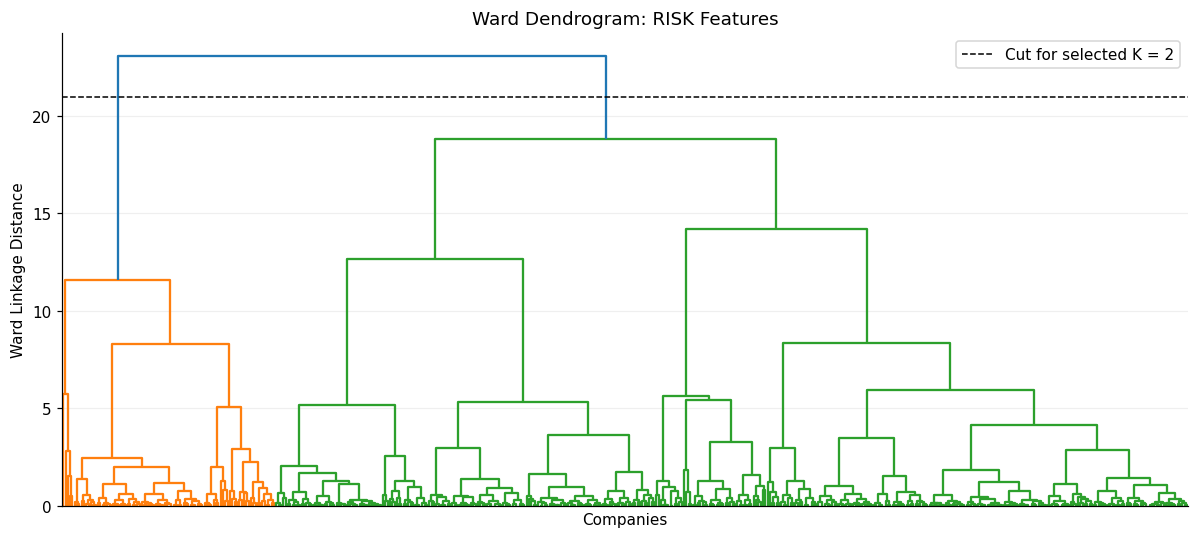

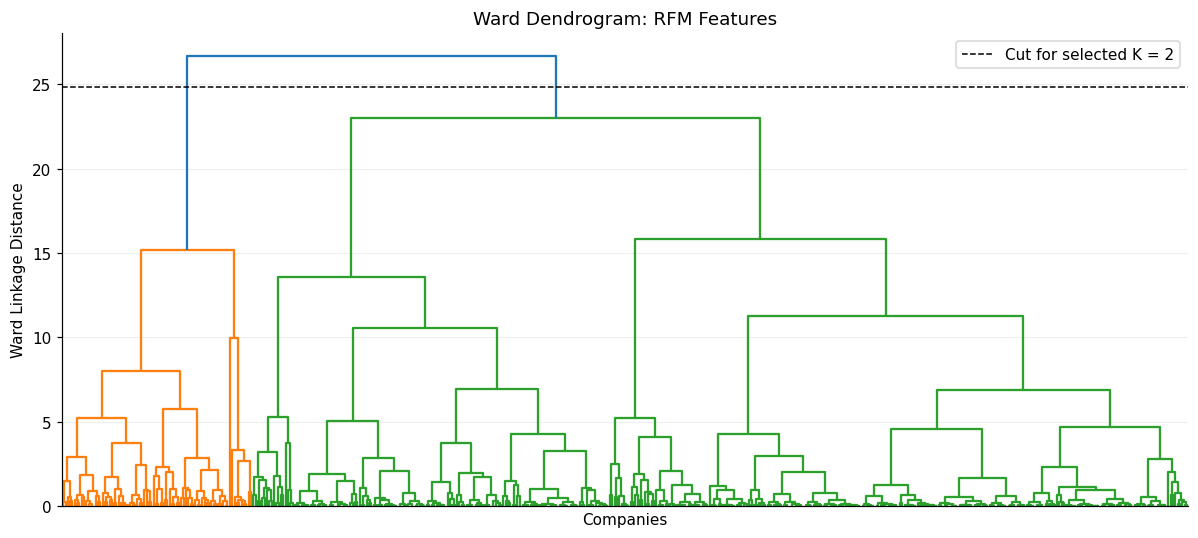

Ward Clustering Evaluation


,FeatureSet,Method,K,Silhouette,MinClusterSize,MaxClusterSize,Selected
0,risk,Ward,2,0.3395,92,394,True
1,risk,Ward,3,0.2738,92,230,False
2,risk,Ward,4,0.2821,48,182,False
3,risk,Ward,5,0.3041,48,182,False
4,risk,Ward,6,0.3204,5,182,False
5,risk,Ward,7,0.3240,5,160,False
6,risk,Ward,8,0.3208,5,160,False
7,rfm,Ward,2,0.3680,82,404,True
8,rfm,Ward,3,0.3040,82,250,False
9,rfm,Ward,4,0.2888,43,207,False


Ward Candidate Cluster Profiles


,FeatureSet,Method,K,Cluster,Size,MeanWeeklyReturn,Median_MeanWeeklyReturn,WeeklyBeta,Median_WeeklyBeta,R,Median_R,F,Median_F,M,Median_M
0,risk,Ward,2,0,394,0.0020,0.0021,0.8979,0.8817,19.6447,11.0,2.9416,3.0,3.020963e+10,1.532516e+10
1,risk,Ward,2,1,92,0.0063,0.0055,1.2981,1.2177,23.6739,11.0,3.1957,3.0,7.878092e+10,2.418413e+10
2,risk,Ward,3,0,230,0.0015,0.0017,1.1096,1.0384,18.9304,11.0,3.0565,3.0,3.380100e+10,1.411142e+10
3,risk,Ward,3,1,92,0.0063,0.0055,1.2981,1.2177,23.6739,11.0,3.1957,3.0,7.878092e+10,2.418413e+10
4,risk,Ward,3,2,164,0.0029,0.0033,0.6012,0.5777,20.6463,11.0,2.7805,3.0,2.517294e+10,1.764940e+10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
65,rfm,Ward,8,3,43,0.0028,0.0028,1.0081,1.0467,16.8372,11.0,5.3721,5.0,1.496218e+10,1.442997e+10
66,rfm,Ward,8,4,141,0.0025,0.0025,0.9223,0.9183,11.1702,11.0,3.4468,3.0,1.121211e+10,1.078527e+10
67,rfm,Ward,8,5,18,0.0053,0.0046,1.3512,1.2895,17.5000,12.5,4.5556,5.0,3.504407e+11,2.448680e+11
68,rfm,Ward,8,6,66,0.0025,0.0022,0.9336,0.9274,11.0758,11.0,1.8636,2.0,1.085987e+10,1.067576e+10


In [16]:
# Apply Ward clustering to the Risk and RFM sets
(
    features,
    ward_scores,
    ward_profiles,
    ward_cluster_sizes,
    ward_labels,
    ward_candidate_profiles
) = perform_clustering(features, 'Ward')

# Show the evaluation table
print("Ward Clustering Evaluation")
# show the table
display(
    ward_scores.drop(columns='Inertia').round(4)
)

# Show profiles of all candidate clusters
print("Ward Candidate Cluster Profiles")
# show the table
display(ward_candidate_profiles.round(4))

2.3 K-means clustering

In [17]:

# Apply K-means clustering to the Risk and RFM sets
(
    features,
    kmeans_scores,
    kmeans_profiles,
    kmeans_cluster_sizes,
    kmeans_labels,
    kmeans_candidate_profiles
) = perform_clustering(features, 'KMeans')

# Show the K-means evaluation table
print("K-means Clustering Evaluation")
# show the table
display(kmeans_scores.round(4))

# Show the sizes of all candidate clusters
print("K-means Cluster Sizes")
# show the table
display(kmeans_cluster_sizes)

# Merge the Ward and K-means evaluations
all_clustering_scores = pd.concat(
    [ward_scores, kmeans_scores],
    ignore_index=True
)

# Merge the selected cluster profiles
all_cluster_profiles = pd.concat(
    [ward_profiles, kmeans_profiles],
    ignore_index=True
)

# message
print("Both clustering methods completed successfully.")

K-means Clustering Evaluation


,FeatureSet,Method,K,Silhouette,Inertia,MinClusterSize,MaxClusterSize,Selected
0,risk,KMeans,2,0.3869,621.6344,143,343,True
1,risk,KMeans,3,0.3289,461.1787,119,202,False
2,risk,KMeans,4,0.3270,371.5770,40,160,False
3,risk,KMeans,5,0.3406,309.6130,27,166,False
4,risk,KMeans,6,0.3349,265.0970,5,156,False
5,risk,KMeans,7,0.3315,227.4762,5,143,False
6,risk,KMeans,8,0.3542,194.3616,5,136,False
7,rfm,KMeans,2,0.4231,1066.8319,68,418,True
8,rfm,KMeans,3,0.3250,796.6144,64,270,False
9,rfm,KMeans,4,0.3409,609.8325,61,212,False


K-means Cluster Sizes


,FeatureSet,Method,K,Cluster,Size
0,risk,KMeans,2,0,143
1,risk,KMeans,2,1,343
2,risk,KMeans,3,0,202
3,risk,KMeans,3,1,165
4,risk,KMeans,3,2,119
...,...,...,...,...,...
65,rfm,KMeans,8,3,66
66,rfm,KMeans,8,4,1
67,rfm,KMeans,8,5,11
68,rfm,KMeans,8,6,140


Both clustering methods completed successfully.


In [18]:
# Show the merged evaluation results
print("Comparison of clustering methods")
# show the table
display(all_clustering_scores.round(4))

# Show the merged cluster profiles
print("Selected Cluster Profiles")
# show the table
display(all_cluster_profiles.round(4))

# Cluster sizes for Ward and K-means
print("Ward cluster sizes")
# show the table
display(ward_cluster_sizes)

# label
print("K-means cluster sizes")
# show the table
display(kmeans_cluster_sizes)

Comparison of clustering methods


,FeatureSet,Method,K,Silhouette,Inertia,MinClusterSize,MaxClusterSize,Selected
0,risk,Ward,2,0.3395,NaN,92,394,True
1,risk,Ward,3,0.2738,NaN,92,230,False
2,risk,Ward,4,0.2821,NaN,48,182,False
3,risk,Ward,5,0.3041,NaN,48,182,False
4,risk,Ward,6,0.3204,NaN,5,182,False
5,risk,Ward,7,0.3240,NaN,5,160,False
6,risk,Ward,8,0.3208,NaN,5,160,False
7,rfm,Ward,2,0.3680,NaN,82,404,True
8,rfm,Ward,3,0.3040,NaN,82,250,False
9,rfm,Ward,4,0.2888,NaN,43,207,False


Selected Cluster Profiles


,FeatureSet,Method,Cluster,Size,MeanWeeklyReturn,Median_MeanWeeklyReturn,WeeklyBeta,Median_WeeklyBeta,R,Median_R,F,Median_F,M,Median_M
0,risk,Ward,0,394,0.0020,0.0021,0.8979,0.8817,19.6447,11.0,2.9416,3.0,3.020963e+10,1.532516e+10
1,risk,Ward,1,92,0.0063,0.0055,1.2981,1.2177,23.6739,11.0,3.1957,3.0,7.878092e+10,2.418413e+10
2,rfm,Ward,0,404,0.0029,0.0027,0.9666,0.9350,12.7153,11.0,3.1708,3.0,3.783020e+10,1.604728e+10
3,rfm,Ward,1,82,0.0029,0.0024,1.0089,1.0466,58.3049,54.5,2.0976,2.0,4.715898e+10,1.784903e+10
4,risk,KMeans,0,143,0.0053,0.0049,1.3505,1.2781,22.6364,11.0,3.1469,3.0,8.143839e+10,2.552367e+10
5,risk,KMeans,1,343,0.0018,0.0019,0.8166,0.8340,19.4781,11.0,2.9242,3.0,2.187973e+10,1.420560e+10
6,rfm,KMeans,0,418,0.0028,0.0027,0.9723,0.9389,13.4234,11.0,3.1866,3.0,3.269100e+10,1.556962e+10
7,rfm,KMeans,1,68,0.0030,0.0025,0.9823,1.0087,63.3382,55.0,1.7794,2.0,8.067057e+10,2.225004e+10


Ward cluster sizes


,FeatureSet,Method,K,Cluster,Size
0,risk,Ward,2,0,394
1,risk,Ward,2,1,92
2,risk,Ward,3,0,230
3,risk,Ward,3,1,92
4,risk,Ward,3,2,164
...,...,...,...,...,...
65,rfm,Ward,8,3,43
66,rfm,Ward,8,4,141
67,rfm,Ward,8,5,18
68,rfm,Ward,8,6,66


K-means cluster sizes


,FeatureSet,Method,K,Cluster,Size
0,risk,KMeans,2,0,143
1,risk,KMeans,2,1,343
2,risk,KMeans,3,0,202
3,risk,KMeans,3,1,165
4,risk,KMeans,3,2,119
...,...,...,...,...,...
65,rfm,KMeans,8,3,66
66,rfm,KMeans,8,4,1
67,rfm,KMeans,8,5,11
68,rfm,KMeans,8,6,140


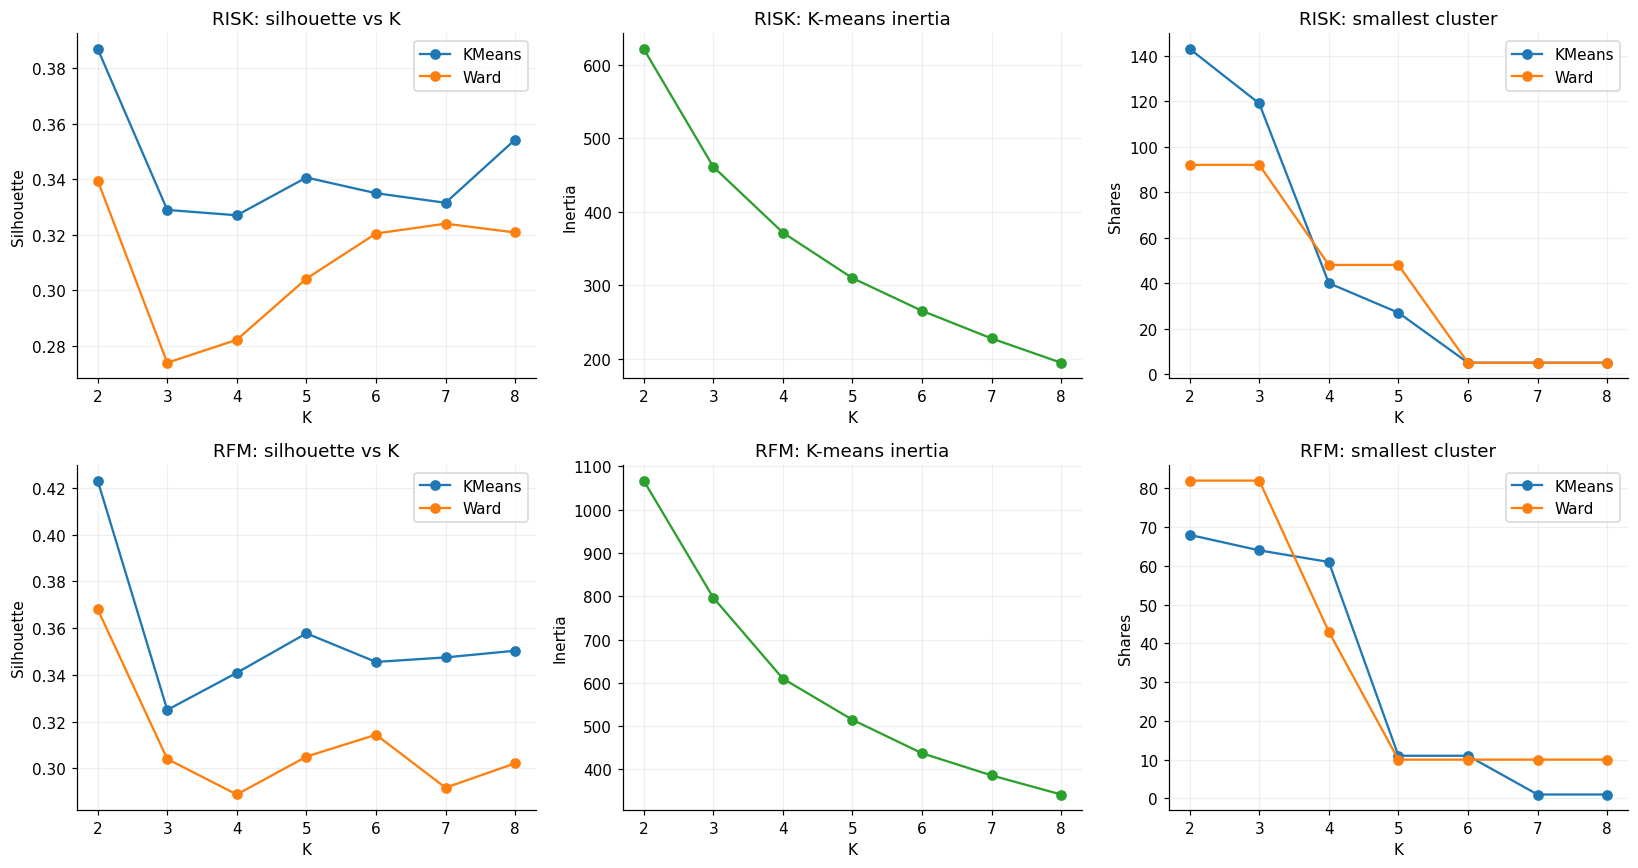

In [19]:
# K-selection diagnostics: silhouette (both methods), K-means inertia (elbow) and smallest cluster size
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
# one row of plots per feature set
for row, set_name in enumerate(['risk', 'rfm']):
    # scores of this feature set
    sub = all_clustering_scores[all_clustering_scores['FeatureSet'] == set_name]
    # one line per method
    for method, grp in sub.groupby('Method'):
        # silhouette against K
        axes[row, 0].plot(grp['K'], grp['Silhouette'], marker='o', label=method)
        # smallest cluster size against K
        axes[row, 2].plot(grp['K'], grp['MinClusterSize'], marker='o', label=method)
    # K-means rows only
    km = sub[sub['Method'] == 'KMeans']
    # inertia against K (elbow plot)
    axes[row, 1].plot(km['K'], km['Inertia'], marker='o', color='tab:green')
    # titles and labels
    axes[row, 0].set(title=f'{set_name.upper()}: silhouette vs K', xlabel='K', ylabel='Silhouette')
    # titles and labels
    axes[row, 1].set(title=f'{set_name.upper()}: K-means inertia', xlabel='K', ylabel='Inertia')
    # titles and labels
    axes[row, 2].set(title=f'{set_name.upper()}: smallest cluster', xlabel='K', ylabel='Shares')
    # legends
    axes[row, 0].legend()
    # legends
    axes[row, 2].legend()
# show and close the figure
display_chart(fig)


2.4 Cluster profiles and algorithm comparison

Final Cluster Profiles


,FeatureSet,Method,Cluster,Size,MeanWeeklyReturn,Median_MeanWeeklyReturn,WeeklyBeta,Median_WeeklyBeta,R,Median_R,F,Median_F,M,Median_M
0,risk,Ward,0,394,0.0020,0.0021,0.8979,0.8817,19.6447,11.0,2.9416,3.0,3.020963e+10,1.532516e+10
1,risk,Ward,1,92,0.0063,0.0055,1.2981,1.2177,23.6739,11.0,3.1957,3.0,7.878092e+10,2.418413e+10
2,rfm,Ward,0,404,0.0029,0.0027,0.9666,0.9350,12.7153,11.0,3.1708,3.0,3.783020e+10,1.604728e+10
3,rfm,Ward,1,82,0.0029,0.0024,1.0089,1.0466,58.3049,54.5,2.0976,2.0,4.715898e+10,1.784903e+10
4,risk,KMeans,0,143,0.0053,0.0049,1.3505,1.2781,22.6364,11.0,3.1469,3.0,8.143839e+10,2.552367e+10
5,risk,KMeans,1,343,0.0018,0.0019,0.8166,0.8340,19.4781,11.0,2.9242,3.0,2.187973e+10,1.420560e+10
6,rfm,KMeans,0,418,0.0028,0.0027,0.9723,0.9389,13.4234,11.0,3.1866,3.0,3.269100e+10,1.556962e+10
7,rfm,KMeans,1,68,0.0030,0.0025,0.9823,1.0087,63.3382,55.0,1.7794,2.0,8.067057e+10,2.225004e+10


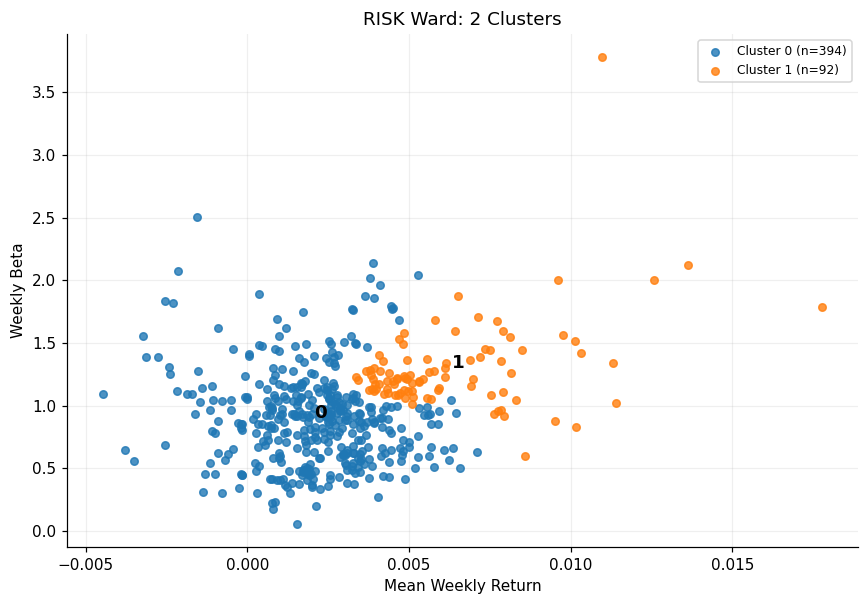

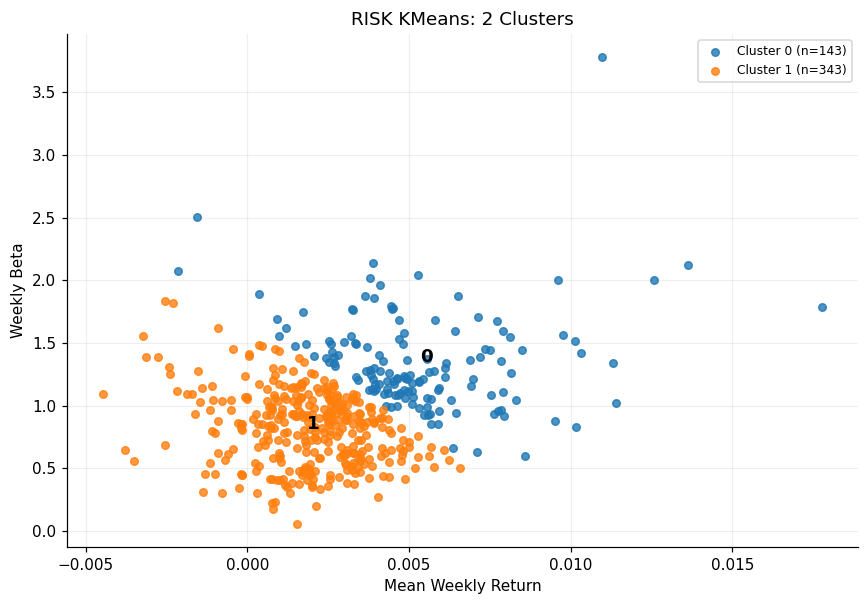

RISK algorithm agreement (ARI): 0.5976


risk_kmeans,0,1
risk_ward,,
0,51,343
1,92,0


,PC1,PC2
R,0.711,0.023
F,-0.650,0.402
LogM,0.268,0.915


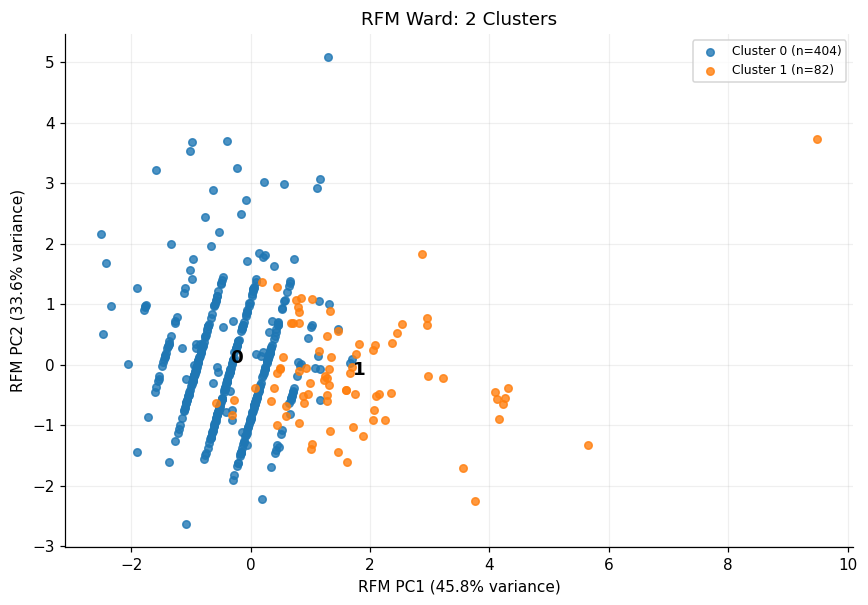

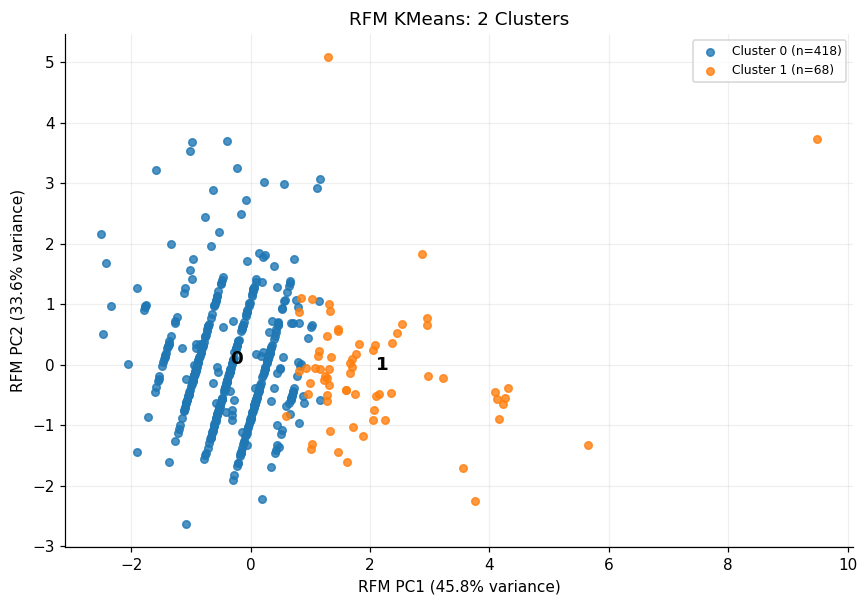

RFM algorithm agreement (ARI): 0.6998


rfm_kmeans,0,1
rfm_ward,,
0,396,8
1,22,60


In [20]:
# PCA is used to plot the three RFM features in 2D
from sklearn.decomposition import PCA

# Show the chosen cluster profiles
print("Final Cluster Profiles")
# show the table
display(all_cluster_profiles.round(4))

# Visualise the Risk and RFM results
for set_name in ['risk', 'rfm']:

    # Standardised inputs for this set
    model_input, input_columns = get_model_data(set_name)

    # Plot each clustering algorithm
    for algo_name in ['Ward', 'KMeans']:

        # Column with the cluster labels
        label_column = (
            f'{set_name}_{algo_name.lower()}'
        )

        # Labels as an array
        label_array = features[label_column].to_numpy()

        # Number of distinct clusters
        n_groups = len(np.unique(label_array))

        # Create the figure
        fig, ax = plt.subplots(figsize=(8, 5.6))

        # Choose the plotting axes
        if set_name == 'risk':

            # Raw Risk variables are plotted directly
            x_data = features['MeanWeeklyReturn']
            # beta on the y-axis
            y_data = features['WeeklyBeta']

            # axis labels
            x_title = 'Mean Weekly Return'
            # axis labels
            y_title = 'Weekly Beta'

        else:

            # Reduce the three RFM features to two components
            pca_fit = PCA(n_components=2)

            # PCA scores (the 2D coordinates)
            pca_scores = pca_fit.fit_transform(model_input)

            # Show how each standardised RFM feature loads on the two components
            if algo_name == 'Ward':
                # show the table
                display(pd.DataFrame(
                    pca_fit.components_.T, index=input_columns, columns=['PC1', 'PC2']
                ).round(3))

            # PC1 on the x-axis
            x_data = pca_scores[:, 0]
            # PC2 on the y-axis
            y_data = pca_scores[:, 1]

            # Include the variance explained in the labels
            x_title = (
                f'RFM PC1 '
                f'({pca_fit.explained_variance_ratio_[0]:.1%} variance)'
            )

            # y-axis label with variance explained
            y_title = (
                f'RFM PC2 '
                f'({pca_fit.explained_variance_ratio_[1]:.1%} variance)'
            )

        # Scatter each cluster separately
        for cluster_id in sorted(set(label_array)):

            # True for shares in this cluster
            row_mask = (
                label_array == cluster_id
            )

            # draw this cluster's points
            ax.scatter(
                np.asarray(x_data)[row_mask],
                np.asarray(y_data)[row_mask],
                s=24,
                label=f'Cluster {cluster_id} (n={row_mask.sum()})',
                alpha=0.8
            )

            # Label each cluster at its centre
            ax.annotate(
                str(cluster_id),
                (np.asarray(x_data)[row_mask].mean(), np.asarray(y_data)[row_mask].mean()),
                fontsize=12, fontweight='bold'
            )

        # Titles and axis labels
        ax.set(
            xlabel=x_title,
            ylabel=y_title,
            title=f'{set_name.upper()} {algo_name}: '
                  f'{n_groups} Clusters'
        )

        # show the legend
        ax.legend(fontsize=8)

        # Render the chart
        display_chart(fig)

    # Ward vs K-means labels
    ward_assign = features[f'{set_name}_ward']
    # K-means labels
    kmeans_assign = features[f'{set_name}_kmeans']

    # Adjusted Rand Index between the two
    ari_value = adjusted_rand_score(
        ward_assign,
        kmeans_assign
    )

    # print the result
    print(
        f'{set_name.upper()} algorithm agreement (ARI): '
        f'{ari_value:.4f}'
    )

    # Cross-tabulate the two assignments
    display(
        pd.crosstab(
            ward_assign,
            kmeans_assign
        )
    )

2.5 RFM sensivity and correlated inputs

RFM Correlation Analysis


,R,F,LogM
R,1.0000,-0.3463,0.1524
F,-0.3463,1.0000,0.0128
LogM,0.1524,0.0128,1.0000


Spearman correlations


,R,F,LogM
R,1.0000,-0.1958,0.1372
F,-0.1958,1.0000,-0.0476
LogM,0.1372,-0.0476,1.0000


Variance share of each principal component (standardised R, F, LogM): [0.458 0.336 0.206]


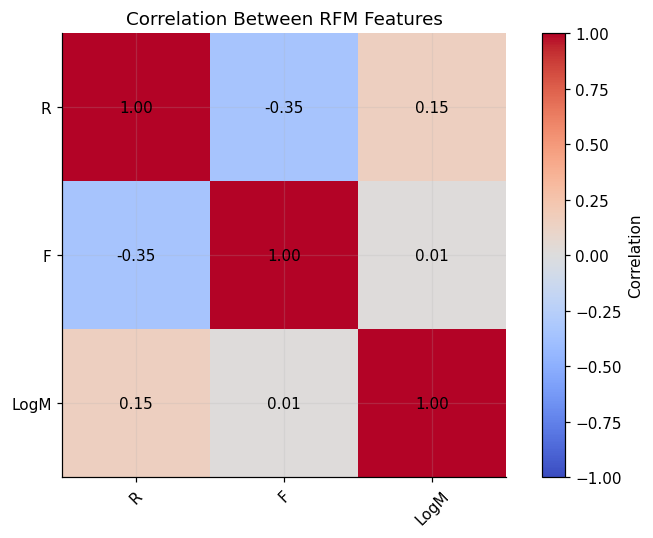

In [21]:
# The three RFM features
rfm_columns = features[['R', 'F', 'LogM']]

# Pairwise correlations
corr_matrix = rfm_columns.corr()

# Show the correlations
print("RFM Correlation Analysis")
# show the table
display(corr_matrix.round(4))

# Rank-based check, and how much variance the first principal component of the standardised inputs holds
print("Spearman correlations")
# show the table
display(rfm_columns.corr(method='spearman').round(4))
# share of variance of each principal component
pc_share = PCA().fit(StandardScaler().fit_transform(rfm_columns)).explained_variance_ratio_
# print the result
print("Variance share of each principal component (standardised R, F, LogM):", np.round(pc_share, 3))

# Draw the correlation heatmap
fig, ax = plt.subplots(figsize=(7, 5))

# draw the correlation heatmap
heat_img = ax.imshow(
    corr_matrix,
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)

# Tick positions for the feature names
ax.set_xticks(range(len(corr_matrix.columns)))
# tick positions
ax.set_yticks(range(len(corr_matrix.index)))

# tick labels
ax.set_xticklabels(
    corr_matrix.columns,
    rotation=45
)

# tick labels
ax.set_yticklabels(
    corr_matrix.index
)

# Print each coefficient inside its cell
for row_pos in range(len(corr_matrix)):
    # write each coefficient inside its cell
    for col_pos in range(len(corr_matrix.columns)):

        # the coefficient
        ax.text(
            col_pos,
            row_pos,
            f'{corr_matrix.iloc[row_pos, col_pos]:.2f}',
            ha='center',
            va='center'
        )

# title
ax.set_title('Correlation Between RFM Features')

# colour scale
fig.colorbar(
    heat_img,
    ax=ax,
    label='Correlation'
)

# show and close the figure
display_chart(fig)

In [22]:
# Cluster count picked by the original RFM Ward model
ward_k = features['rfm_ward'].nunique()

# Keep only Recency and Frequency
rf_only = features[['R', 'F']]

# Standardise the two remaining features
rf_standardiser = StandardScaler()

# standardise R and F afresh
rf_scaled = rf_standardiser.fit_transform(
    rf_only
)

# Ward clustering with Monetary removed
rf_ward_model = AgglomerativeClustering(
    n_clusters=ward_k,
    linkage='ward'
)

# Store the new assignments
features['rfm_ward_without_m'] = (
    rf_ward_model.fit_predict(rf_scaled)
)

# Agreement between the original and the reduced model
ari_without_m = adjusted_rand_score(
    features['rfm_ward'],
    features['rfm_ward_without_m']
)

# Show the ARI
print(
    "ARI after removing Monetary:",
    round(ari_without_m, 4)
)

# Compare profiles with and without Monetary
for label_column in [
    'rfm_ward',
    'rfm_ward_without_m'
]:

    # print the result
    print("\nResults for:", label_column)

    # Count and average RFM values per cluster
    group_summary = features.groupby(
        label_column
    ).agg(
        Count=('Ticker', 'size'),
        MeanM=('M', 'mean'),
        MedianM=('M', 'median'),
        MeanR=('R', 'mean'),
        MeanF=('F', 'mean')
    )

    # show the table
    display(group_summary.round(4))

# Membership cross-tabulation, traded-value profile and fit of the R,F-only solution
display(pd.crosstab(features['rfm_ward'], features['rfm_ward_without_m'],
                    rownames=['with M'], colnames=['without M']))

# average daily traded value (USD) = M / 60 sessions
features['AvgDailyTradedValue'] = features['M'] / 60
# show the table
display(features.groupby('rfm_ward_without_m')['AvgDailyTradedValue'].agg(['mean', 'median']).round(0))

# print the result
print("Silhouette of the R,F-only solution:",
      round(silhouette_score(rf_scaled, features['rfm_ward_without_m']), 4))


ARI after removing Monetary: 0.8735

Results for: rfm_ward


,Count,MeanM,MedianM,MeanR,MeanF
rfm_ward,,,,,
0,404,3.783020e+10,1.604728e+10,12.7153,3.1708
1,82,4.715898e+10,1.784903e+10,58.3049,2.0976



Results for: rfm_ward_without_m


,Count,MeanM,MedianM,MeanR,MeanF
rfm_ward_without_m,,,,,
0,397,3.780680e+10,1.546400e+10,12.3023,3.2091
1,89,4.652963e+10,2.084781e+10,56.5618,2.0112


without M,0,1
with M,,
0,394,10
1,3,79


,mean,median
rfm_ward_without_m,,
0,630113356.0,257733301.0
1,775493841.0,347463505.0


Silhouette of the R,F-only solution: 0.5239


In [23]:
# Write the final feature table with cluster labels to disk
features.to_csv(
    results_dir / 'feature_table_with_clusters.csv',
    index=False
)

# Write the clustering evaluation results
all_clustering_scores.to_csv(
    results_dir / 'clustering_evaluation.csv',
    index=False
)

# Write the selected cluster profiles
all_cluster_profiles.to_csv(
    results_dir / 'cluster_profiles.csv',
    index=False
)

# Write the RFM correlations
corr_matrix.to_csv(
    results_dir / 'rfm_correlation.csv'
)

# Write the cluster sizes
all_cluster_sizes = pd.concat(
    [ward_cluster_sizes, kmeans_cluster_sizes],
    ignore_index=True
)

# save the cluster sizes
all_cluster_sizes.to_csv(
    results_dir / 'cluster_sizes.csv',
    index=False
)

# Weekly returns used for beta (reproducibility)
stock_returns[features['Ticker']].to_csv(results_dir / 'weekly_returns_included_shares.csv')
# save the benchmark weekly returns
index_returns.to_csv(results_dir / 'weekly_returns_benchmark.csv', header=['GSPC_weekly_return'])

# Columns shown in the final overview
overview_columns = [
    'Ticker',
    *metrics,
    'risk_ward',
    'risk_kmeans',
    'rfm_ward',
    'rfm_kmeans',
    'rfm_ward_without_m'
]

# show the table
display(features[overview_columns])

# print the result
print("Task 2 completed successfully!")
# print the result
print("Final companies analysed:", len(features))
# print the result
print("Results saved in:", results_dir)

,Ticker,MeanWeeklyReturn,WeeklyBeta,R,F,M,risk_ward,risk_kmeans,rfm_ward,rfm_kmeans,rfm_ward_without_m
0,MMM,0.001142,0.869079,11,4,2.599146e+10,0,1,0,0,0
1,AOS,0.001991,1.042805,11,2,4.748980e+09,0,1,0,0,0
2,ABT,0.000971,0.583543,11,1,3.523027e+10,0,1,0,0,0
3,ABBV,0.003749,0.425366,11,3,6.837054e+10,0,1,0,0,0
4,ACN,0.002376,1.143300,11,2,5.199430e+10,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
481,XYL,0.001358,1.138380,36,3,1.017679e+10,0,1,1,0,1
482,YUM,0.001807,0.631435,56,1,1.339492e+10,0,1,1,1,1
483,ZBRA,0.001181,1.618418,11,4,8.326927e+09,0,0,0,0,0
484,ZBH,-0.001105,0.798203,11,2,9.609458e+09,0,1,0,0,0


Task 2 completed successfully!
Final companies analysed: 486
Results saved in: /content/analysis/results


### Task 3 – Business Intelligence and Critical Review

3.2.1 Cluster profiles and sector composition

(3.1 Data mart design is written in the report, max 200 words - no code needed.)


Sector composition: risk_ward


risk_ward,0,1
Sector,,
Communication Services,15,5
Consumer Discretionary,36,11
Consumer Staples,32,0
Energy,16,4
Financials,61,13
Health Care,56,2
Industrials,57,21
Information Technology,45,29
Materials,20,3


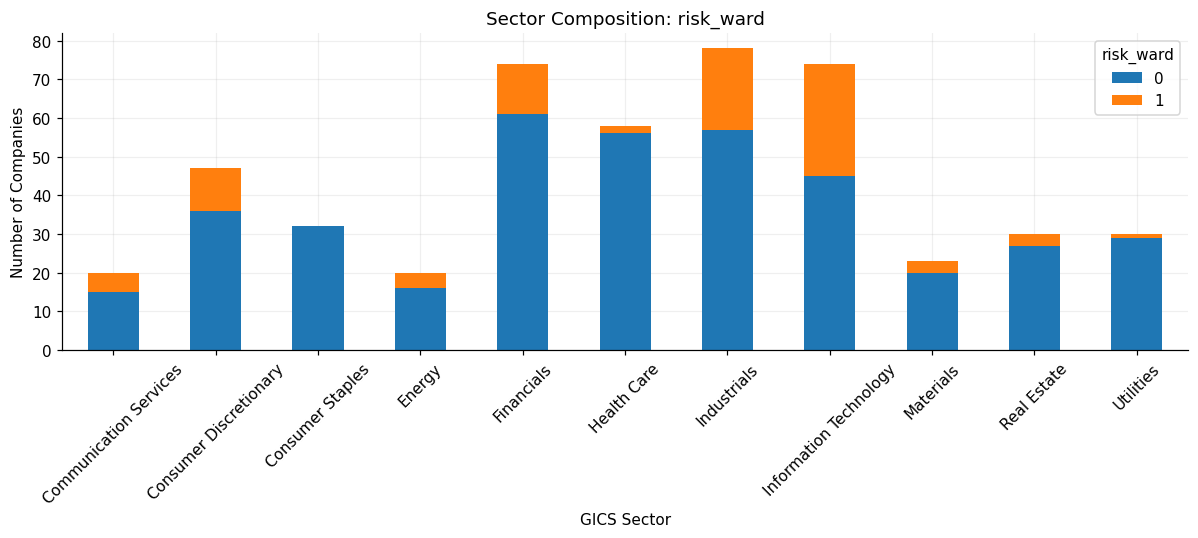


Sector composition: risk_kmeans


risk_kmeans,0,1
Sector,,
Communication Services,5,15
Consumer Discretionary,23,24
Consumer Staples,1,31
Energy,9,11
Financials,17,57
Health Care,2,56
Industrials,29,49
Information Technology,48,26
Materials,4,19


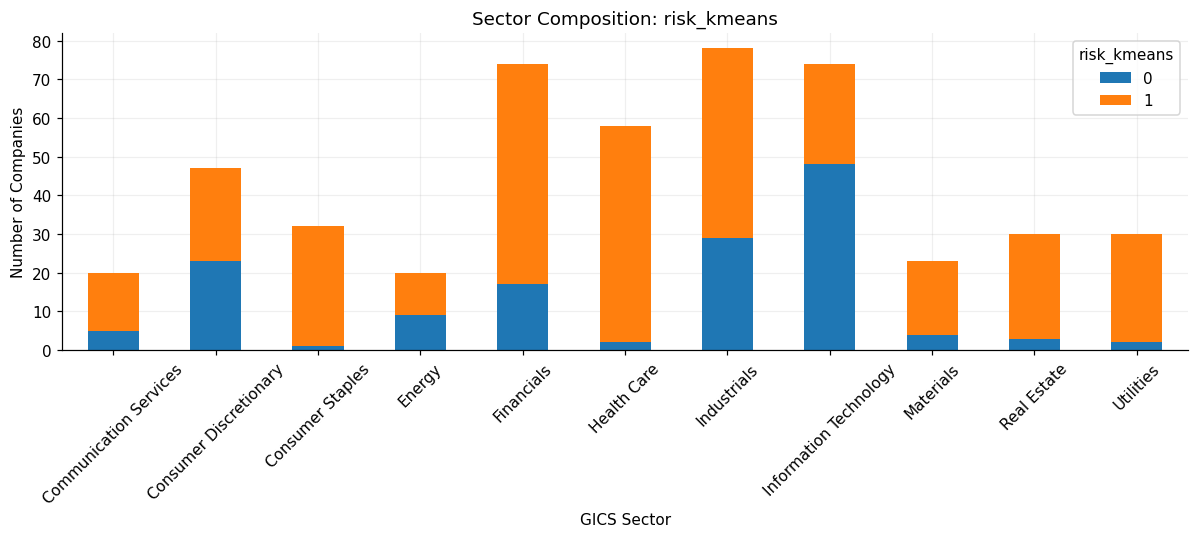


Sector composition: rfm_ward


rfm_ward,0,1
Sector,,
Communication Services,16,4
Consumer Discretionary,38,9
Consumer Staples,25,7
Energy,18,2
Financials,64,10
Health Care,49,9
Industrials,72,6
Information Technology,56,18
Materials,15,8


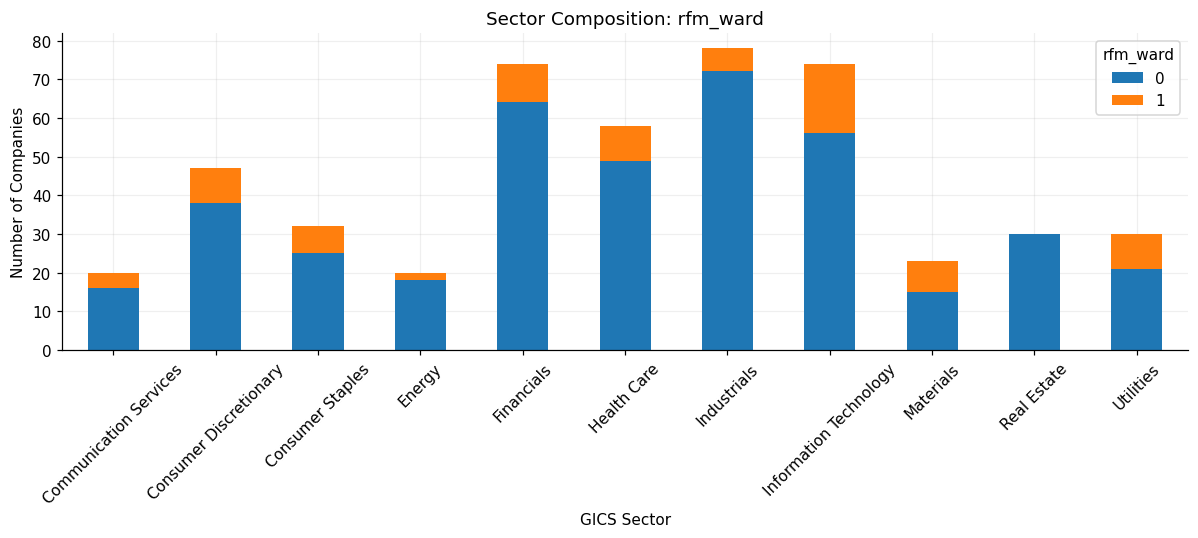


Sector composition: rfm_kmeans


rfm_kmeans,0,1
Sector,,
Communication Services,18,2
Consumer Discretionary,39,8
Consumer Staples,27,5
Energy,19,1
Financials,64,10
Health Care,50,8
Industrials,73,5
Information Technology,60,14
Materials,17,6


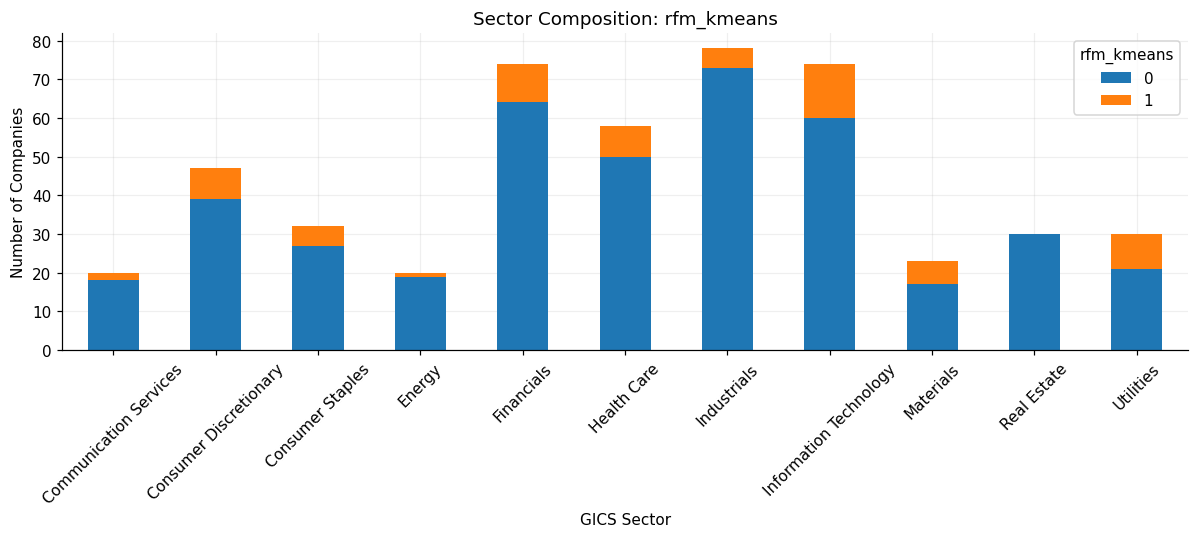

risk_ward vs rfm_ward: ARI = 0.0285


rfm_ward,0,1
risk_ward,,
0,331,63
1,73,19


risk_ward vs rfm_kmeans: ARI = 0.0192


rfm_kmeans,0,1
risk_ward,,
0,341,53
1,77,15


risk_kmeans vs rfm_ward: ARI = 0.0135


rfm_ward,0,1
risk_kmeans,,
0,116,27
1,288,55


risk_kmeans vs rfm_kmeans: ARI = 0.0045


rfm_kmeans,0,1
risk_kmeans,,
0,122,21
1,296,47


In [24]:
# The four clustering outputs to examine
label_columns = [
    'risk_ward',
    'risk_kmeans',
    'rfm_ward',
    'rfm_kmeans'
]

# Sector breakdown for each clustering output
for label_column in label_columns:

    # print the result
    print("\nSector composition:", label_column)

    # Sector-by-cluster count table
    sector_counts = pd.crosstab(
        features['Sector'],
        features[label_column]
    )

    # Show the counts
    display(sector_counts)

    # Stacked bar chart of the counts
    fig, ax = plt.subplots(figsize=(11, 5))

    # stacked bar of the counts
    sector_counts.plot.bar(
        stacked=True,
        ax=ax,
        rot=45
    )

    # Titles and axis labels
    ax.set(
        title=f'Sector Composition: {label_column}',
        xlabel='GICS Sector',
        ylabel='Number of Companies'
    )

    # Render using the display_chart helper
    display_chart(fig)

# Compare return/beta clusters with RFM clusters on the same shares
for r_col in ['risk_ward', 'risk_kmeans']:
    # compare with each RFM clustering
    for f_col in ['rfm_ward', 'rfm_kmeans']:
        # print the result
        print(f"{r_col} vs {f_col}: ARI = {adjusted_rand_score(features[r_col], features[f_col]):.4f}")
        # show the table
        display(pd.crosstab(features[r_col], features[f_col]))


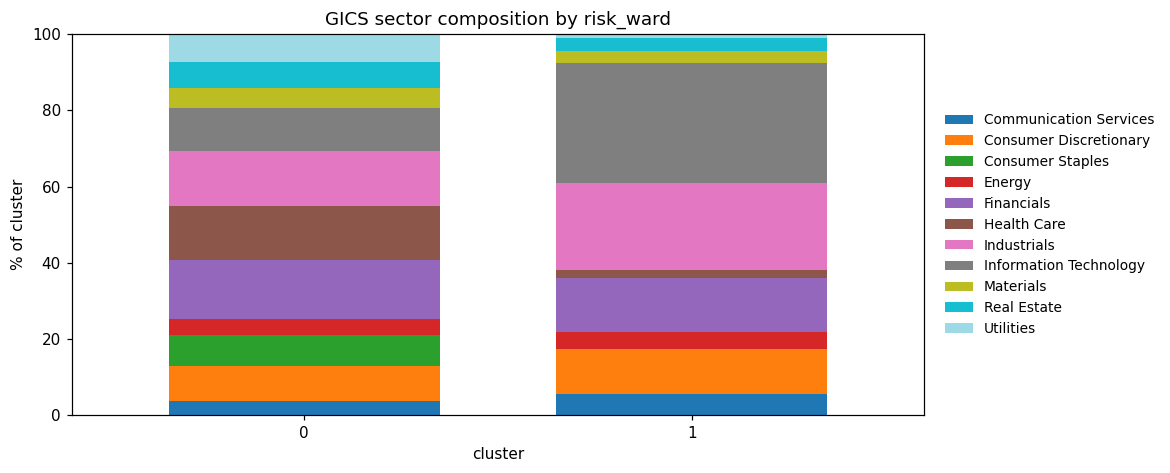

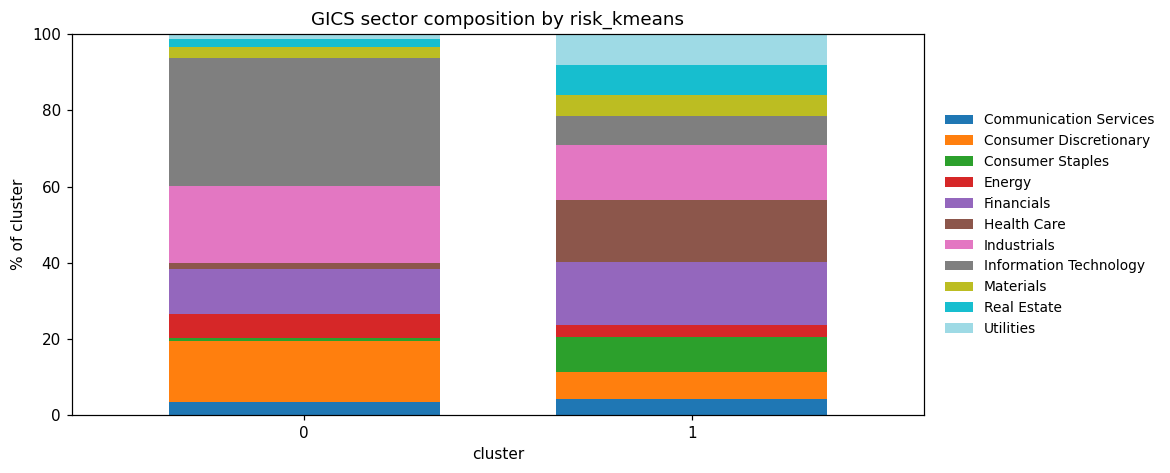

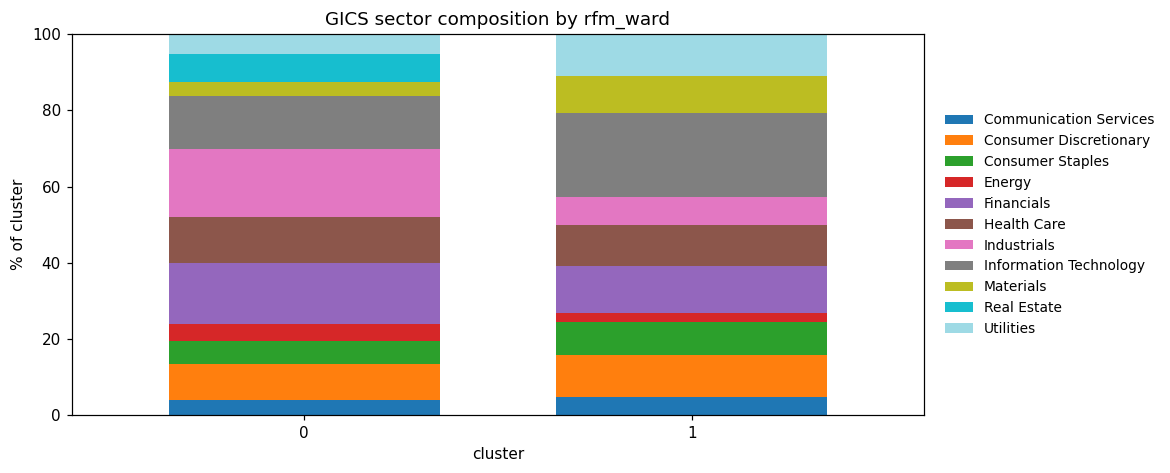

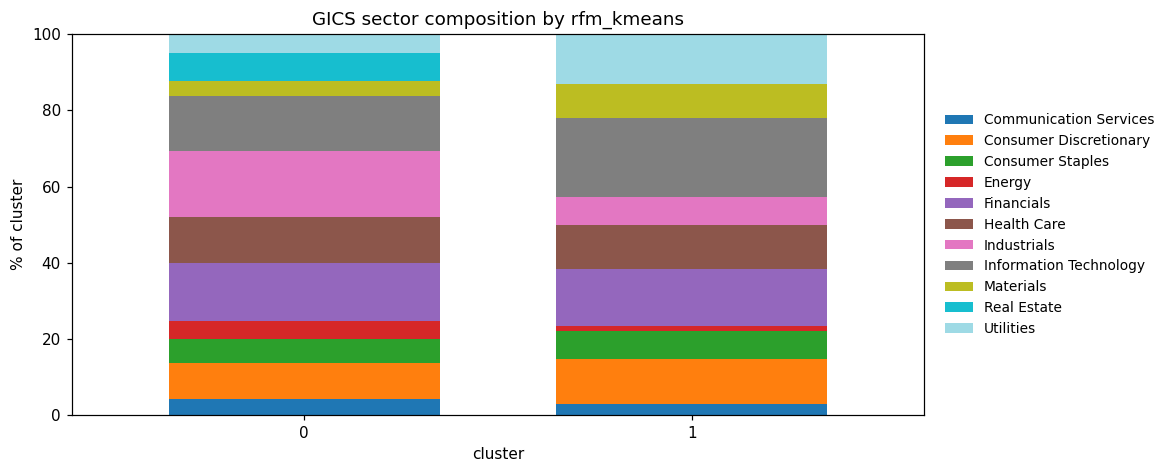

In [25]:
# 100% stacked sector composition by cluster (one chart per clustering solution)
sector_colors = list(plt.cm.tab10.colors) + [plt.cm.tab20.colors[19]]   # 11 GICS sectors

# repeat for each of the four clusterings
for label_column in label_columns:

    # Share of each sector inside every cluster (rows sum to 100)
    pct = pd.crosstab(features[label_column], features['Sector'], normalize='index') * 100

    # create the figure
    fig, ax = plt.subplots(figsize=(10, 4.5))
    # draw the 100% stacked bars
    pct.plot.bar(
        stacked=True, ax=ax, rot=0, width=0.7,
        color=sector_colors[:pct.shape[1]], edgecolor='none'
    )

    # titles and axis labels
    ax.set(
        title=f'GICS sector composition by {label_column}',
        xlabel='cluster', ylabel='% of cluster', ylim=(0, 100)
    )
    # no grid lines
    ax.grid(False)
    # show the full frame
    for side in ['top', 'right']:
        # show the frame line
        ax.spines[side].set_visible(True)

    # Legend outside the plot, on the right
    ax.legend(loc='center left', bbox_to_anchor=(1.01, 0.5), frameon=False, fontsize=9)

    # Save first (keeps the legend in the file), then show
    fig.savefig(results_dir / f'sector_composition_{label_column}.png', dpi=200, bbox_inches='tight')
    # draw the figure
    plt.show()
    # free the memory
    plt.close(fig)


**3.2.2 and 3.2.3 Supporting evidence for the review**

3.2.2 Sensitivity findings and business uses

In [26]:

# Sector information must be present
assert 'Sector' in features.columns, "Sector information is missing."

# Columns needed for the rest of the analysis
needed_columns = [
    'Ticker',
    'Sector',
    'risk_ward',
    'risk_kmeans',
    'rfm_ward',
    'rfm_kmeans'
]

# Confirm that none of them is missing
absent_columns = [
    col for col in needed_columns
    if col not in features.columns
]

# all needed columns must exist
assert not absent_columns, (
    f"Missing columns: {absent_columns}"
)

# Preview the sector and cluster columns
display(features[needed_columns].head(10))

# print the result
print("Task 3 data is ready.")

,Ticker,Sector,risk_ward,risk_kmeans,rfm_ward,rfm_kmeans
0,MMM,Industrials,0,1,0,0
1,AOS,Industrials,0,1,0,0
2,ABT,Health Care,0,1,0,0
3,ABBV,Health Care,0,1,0,0
4,ACN,Information Technology,0,1,0,0
5,ADBE,Information Technology,0,0,0,0
6,AMD,Information Technology,0,0,0,0
7,AES,Utilities,0,1,1,1
8,AFL,Financials,0,1,0,0
9,A,Health Care,0,1,0,0


Task 3 data is ready.


In [27]:
# Percentage of each sector inside every cluster
for label_column in label_columns:

    # print the result
    print("\nPercentage distribution:", label_column)

    # Row-normalised sector shares per cluster
    sector_shares = pd.crosstab(
        features[label_column],
        features['Sector'],
        normalize='index'
    ) * 100

    # Show the percentages
    display(sector_shares.round(2))

# Over/under-representation: cluster sector share divided by the sector share of all shares (1 = same as overall)
overall_share = features['Sector'].value_counts(normalize=True) * 100

# repeat for each of the four clusterings
for label_column in label_columns:
    # % of each sector inside every cluster
    share = pd.crosstab(features[label_column], features['Sector'], normalize='index') * 100
    # print the result
    print("\nSector lift vs overall mix:", label_column)
    # show the table
    display(share.div(overall_share, axis=1).round(2))



Percentage distribution: risk_ward


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
risk_ward,,,,,,,,,,,
0,3.81,9.14,8.12,4.06,15.48,14.21,14.47,11.42,5.08,6.85,7.36
1,5.43,11.96,0.00,4.35,14.13,2.17,22.83,31.52,3.26,3.26,1.09



Percentage distribution: risk_kmeans


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
risk_kmeans,,,,,,,,,,,
0,3.50,16.08,0.70,6.29,11.89,1.40,20.28,33.57,2.80,2.10,1.40
1,4.37,7.00,9.04,3.21,16.62,16.33,14.29,7.58,5.54,7.87,8.16



Percentage distribution: rfm_ward


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
rfm_ward,,,,,,,,,,,
0,3.96,9.41,6.19,4.46,15.84,12.13,17.82,13.86,3.71,7.43,5.20
1,4.88,10.98,8.54,2.44,12.20,10.98,7.32,21.95,9.76,0.00,10.98


... (6 outputs left out)


Sector lift vs overall mix: rfm_ward


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
rfm_ward,,,,,,,,,,,
0,0.96,0.97,0.94,1.08,1.04,1.02,1.11,0.91,0.78,1.2,0.84
1,1.19,1.13,1.30,0.59,0.80,0.92,0.46,1.44,2.06,0.0,1.78



Sector lift vs overall mix: rfm_kmeans


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
rfm_kmeans,,,,,,,,,,,
0,1.05,0.96,0.98,1.10,1.01,1.00,1.09,0.94,0.86,1.16,0.81
1,0.71,1.22,1.12,0.36,0.97,0.99,0.46,1.35,1.86,0.00,2.14


3.2.3 Critical evaluation and limitations

In [28]:
# 3.2.3 Return dependencies: do shares in the same cluster move together?
returns_final = stock_returns[features['Ticker']]
# correlation matrix of weekly returns
corr_returns = returns_final.corr().to_numpy()

# average correlation between different shares in a group
def avg_pairwise_corr(idx):
    # correlations inside the group
    sub = corr_returns[np.ix_(idx, idx)]
    # number of shares in the group
    m = len(idx)
    # give back the table and all result tables
    return (sub.sum() - m) / (m * (m - 1)) if m > 1 else np.nan

# average correlation across all shares
overall_corr = avg_pairwise_corr(np.arange(len(features)))
# results list
dependency_rows = []

# repeat for each of the four clusterings
for label_column in label_columns:
    # each cluster
    for cluster_id in sorted(features[label_column].unique()):
        # positions of the shares in the cluster
        idx = np.where(features[label_column].to_numpy() == cluster_id)[0]
        # store the cluster's result
        dependency_rows.append({
            'Clustering': label_column,
            'Cluster': cluster_id,
            'Size': len(idx),
            'AvgPairwiseCorr': avg_pairwise_corr(idx),
            'AvgPairwiseCorr_AllShares': overall_corr
        })

# show the table
display(pd.DataFrame(dependency_rows).round(3))


,Clustering,Cluster,Size,AvgPairwiseCorr,AvgPairwiseCorr_AllShares
0,risk_ward,0,394,0.297,0.3
1,risk_ward,1,92,0.374,0.3
2,risk_kmeans,0,143,0.372,0.3
3,risk_kmeans,1,343,0.302,0.3
4,rfm_ward,0,404,0.306,0.3
5,rfm_ward,1,82,0.266,0.3
6,rfm_kmeans,0,418,0.305,0.3
7,rfm_kmeans,1,68,0.271,0.3
